# Billboard: Top 10 or Not?

**BA780 Final Project — Team A05**

Team members: Omar Tawfik, Caitlin Jeng, Muhammad Azaan, Xiaoquan Dai

---

### Project proposal

We look at every song that entered the Billboard Hot 100 between  2018 and September 2026.
Our question: what makes some of them reach the **Top 10** while others rank lower? And can we spot
a future Top 10 hit in its **first week on the chart**, using only what a record label knows at that
point?

In the Team Assignment (Phase 1) we tested ten factors, one at a time. In this final phase we go
further: we build a prediction model and test it on years it has never seen, we test the album-drop
effect in a fairer way, we follow how hits move on the chart week by week, we check whether songs
are getting shorter, and we ask whether artists from outside the US do better.

### Data sources, access and licensing

| Source | What we used | Access URL | Licence |
|---|---|---|---|
| Billboard Hot 100 weekly archive (mhollingshead) | every weekly chart, 1958-2026 | https://github.com/mhollingshead/billboard-hot-100 | **No licence given by the repository.** The chart itself belongs to Billboard |
| LRCLIB | song lyrics | https://lrclib.net/docs | **No licence given on the public docs page.** Lyrics belong to their owners |
| MusicBrainz | release dates, release format, genres, song length, artist country | https://musicbrainz.org/doc/MusicBrainz_API | Core data is **CC0 (public domain)** |

We use the two sources without a licence only for this class project, and we don't share the
lyrics or the chart archive.

### How to run this notebook

- **Billboard:** we read `data/raw/all.json` if it is there, otherwise we download it from GitHub
  (44 MB). Either way we only keep charts up to **2026-09-19**, so the results don't change when
  new weeks are added.
- **Lyrics and MusicBrainz:** in Colab, upload `raw_api_data.zip` (4 MB) when asked. On a laptop,
  the files are read from `data/raw/`. The notebook doesn't call any APIs; our scripts in
  `scripts/` collected these files once.

### Tools beyond the course material

Almost everything here uses methods from the class notebooks. These are the exceptions:

| Tool | Where | Why we used it |
|---|---|---|
| `scipy.stats.chi2_contingency` and Cramér's V (`np.sqrt`) | `chi_square_test` helper | tests whether the Top 10 rate is different between groups, and how strong the link is |
| `scipy.stats.mannwhitneyu` | `mann_whitney_test` helper | tests whether a number (like word count) is different for Top 10 songs, without assuming a bell curve |
| `invert_yaxis` | Chart 13 | puts chart position 1 at the top, like the real chart |
| `showfliers=False`, `sharey=True` | Charts 5 and 6 | hides extreme outliers in the box plots; gives the two month panels the same scale |
| `os.path.exists` | Step 1 | checks whether a file is already on disk before reading or uploading it |
| `plt.gca` | Chart 13 | gets the current chart, so we can flip its y-axis |
| `rot=` | Chart 9 | keeps the bar labels horizontal |

In [1]:
# Load the libraries we use.
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno
# scipy is only used for the two significance tests.
from scipy import stats

# Fix the random seed, so the random sample in Step 5 is the same every time.
np.random.seed(42)

## Executive summary

**Goal.** Help a record label decide, in a song's first week, which songs are worth Top 10
marketing money, and which release choices improve the chances.

**Data and methods.** 5,342 songs that entered the Hot 100 between January 2018 and September 2026,
joined to their lyrics (LRCLIB) and release data (MusicBrainz). About one song in ten reaches the
Top 10. We tested each factor with chi-square and Mann-Whitney tests on the 2018-2024 songs. Then we
trained a logistic regression on 2018-2024 and tested it once on the 950 songs from 2025-2026.

**Key findings.**
1. **The artist's record and the genre set the starting odds.** The more Top 10 hits an artist already has, the more likely their next song is to reach the top 10. Artists with no earlier hits had a 5.8% rate compared to 18.5% for artists with ten or more earlier Top 10 hits, which is three times as likely. The difference is significant and the strongest single factor (p < 0.001, V = 0.158). Even on its own, an artist’s track record picks hits more than three times as well as random guessing (19.6% vs 5.9%).

1. **A model built on first-week facts is a useful screening tool.** It flagged 35 test songs and
   15 of them became Top 10 hits (**42.9% precision**). Picking at random gives 5.9%, and a model
   that only knows the artist's past hits gives 19.6%. It caught 15 of the 56 real hits
   (**26.8% recall**).
2. **How a song is released is the biggest thing a label controls.** When we compare songs by the
   same artist, **38 of 63 artists** did better with songs released on their own than with songs
   released in an album drop of five or more. Only 8 did better in drops. Drake: 70.0% alone vs
   26.5% in drops.
3. **Most hits are decided in their first week.** 58.4% of Top 10 hits peak in their debut week.
   That share went up from 46.3% for 2018 debuts to 57.8% in 2025, and recent hits drop off faster.
4. **International stars do better, but only stars.** Among artists who already had hits, acts from
   outside the US reach the Top 10 more often than US acts with the same record (26.8% vs 15.7% at
   ten or more earlier hits). Drake, Bad Bunny and The Weeknd make up 48.4% of those outside-US hits.
5. **Several popular ideas don't hold up.** Lyric style, featured artists, collaborations, explicit
   lyrics and the release month make little or no difference. Songs are getting shorter
   (3:24 → 3:11 minutes:seconds), but hits are not: they are about 8 seconds *longer* than other songs.

**Recommendations.**

- **Release important singles on their own, before the album.** Avoid mid-sized drops: songs in a
  drop of 5-9 songs reach the Top 10 only 2.1% of the time.
- **Spend the marketing money in release week.** There is rarely a second chance.
- **Use the model to rank songs, not to promise hits.** It finds hits about seven times better than
  random, but it still misses most of them.
- **Don't chase surface features** like shorter songs, a guest verse or a "best month".

**Next step.** Score the model again on the full 2026 season once those songs are off the chart, and
add audio and streaming data that a label has before release.

## 1. Introduction & motivation

**The Business Problem** Only about one in ten songs that enter the Hot 100 reaches the Top 10. That is what the radio likes to play, but more importantly, this is where the money likes to go. Labels have to decide how
to release and promote a song before they know how it will do in terms of money and success. "Make a better song" doesn't help
with that decision, but "release this as a single, not as track nine of an album" does. This
notebook measures which choices matter, using only what a label knows in a song's first week.

**How we set up the problem.**

- **One row = one song**, identified by its title and the artist credit it debuted under.
- **Target:** `top10`, whether the song ever reached positions 1-10.
- **Which songs:** songs whose *first* week on the chart is on or after 2018-01-01, so we see every
  song from the start. Songs still on the last chart are left out of every test, because their peak
  isn't final yet.
- **Predictors:** only things known in the debut week: the artist's earlier chart record, genre,
  lyrics, song length, release date, and how many songs the artist released that week.
- **Train and test:** the 2018-2024 songs are used for every test and to train the model. The
  2025-2026 songs are kept aside to test the model once.

**Success criteria.** This phase succeeds if it gives us two things. First, a clean, documented
dataset of every 2018-2026 Hot 100 song, with only first-week predictors. Second, a ranked list of
the factors that really separate Top 10 hits from other songs. We only call a factor meaningful if
the difference is statistically significant (p < 0.05) **and** at least a small effect
(Cramér's V ≥ 0.1), because with thousands of songs even tiny differences can pass a significance
test. For the final phase, success means a prediction model trained on 2018-2024 that finds Top 10
hits in the 2025-2026 songs better than a simple baseline that only uses the artist's history. We
judge it by precision and recall, not accuracy.

## 2. Data description

| File | One row per | Rows | Columns we use |
|---|---|---|---|
| `all.json` (Billboard) | song per chart week | 355,487 rows in 3,555 weekly charts, 1958-2026 | date, song, artist, position |
| `lyrics.csv` (LRCLIB) | chart credit | 5,377 | lyrics text, instrumental flag, length, match score |
| `mb_songs.csv` (MusicBrainz) | chart credit | 5,349 | release date, release format (single, album, EP), length, genres and vote counts, artist IDs, match score |
| `mb_artists.csv` (MusicBrainz) | artist | 1,269 | country, genres and vote counts |

We keep the whole archive back to 1958, even though our songs start in 2018. The reason: to count
an artist's earlier hits we need all of chart history. Drake's count of earlier hits would be wrong
if we only looked back to 2018.

LRCLIB and MusicBrainz were matched to the Billboard songs by name, so every match has a confidence
score from 0 to 100. We trust a match of 72 or more. The chart archive is the backbone; lyrics and MusicBrainz add details about each song.

## 3. Data cleaning

We do all the cleaning in this section, starting from the raw files. Each step prints a before and
after count, so you can see what every change did.

### Step 1. Load and check the data

In Colab, the first cell asks for one upload, `raw_api_data.zip`, and unzips it into `data/raw/`.
On a laptop the CSV files are already there.

In [2]:
# In Colab, upload raw_api_data.zip and unzip it. On our own laptops the files are already in data/raw.
if not os.path.exists('data/raw/lyrics.csv'):
    from google.colab import files
    uploaded = files.upload()
    # unzip can't make two new folders at once, so we make them first.
    !mkdir -p data/raw
    !unzip -o raw_api_data.zip -d data/raw

os.listdir('data/raw')

Saving raw_api_data.zip to raw_api_data.zip
Archive:  raw_api_data.zip
  inflating: data/raw/lyrics.csv     
  inflating: data/raw/mb_songs.csv   
  inflating: data/raw/mb_artists.csv  


['mb_songs.csv', 'mb_artists.csv', 'lyrics.csv']

The Billboard archive is one JSON file with one row per week. Each week holds a list of 100 songs.
We read our local copy if we have one, otherwise the file on GitHub.

In [3]:
# Read the Billboard archive. Each row is one weekly chart with a list of 100 songs.
billboard_url = 'https://raw.githubusercontent.com/mhollingshead/billboard-hot-100/main/all.json'
# The last chart week we use. Weeks added to the archive later are ignored.
last_chart = '2026-09-19'

# Use our local copy if we have one, otherwise download it.
if os.path.exists('data/raw/all.json'):
    charts = pd.read_json('data/raw/all.json')
else:
    charts = pd.read_json(billboard_url)

print('weekly charts downloaded:', len(charts))
charts.head(3)

weekly charts downloaded: 3559


,date,data
0,1958-08-04,"[{'song': 'Poor Little Fool', 'artist': 'Ricky..."
1,1958-08-11,"[{'song': 'Poor Little Fool', 'artist': 'Ricky..."
2,1958-08-18,"[{'song': 'Nel Blu Dipinto Di Blu (Volare)', '..."


A simple `for` loop turns each week's list into one row per song per week. Then we turn the date
column into real dates and keep only the charts up to 2026-09-19.

In [4]:
# Turn each week's list of 100 songs into one row per song per week.
rows = []
for i in range(len(charts)):
    for entry in charts['data'][i]:
        rows.append([charts['date'][i], entry['song'], entry['artist'], entry['this_week']])

weekly = pd.DataFrame(rows, columns=['chart_date', 'title', 'artist', 'position'])
# Change the dates from text to real dates, then drop the weeks after our last chart.
weekly['chart_date'] = pd.to_datetime(weekly['chart_date'])
weekly = weekly[weekly['chart_date'] <= last_chart]

print('weekly charts kept:', len(weekly['chart_date'].unique()))
weekly.head(3)

weekly charts kept: 3555


,chart_date,title,artist,position
0,1958-08-04,Poor Little Fool,Ricky Nelson,1
1,1958-08-04,Patricia,Perez Prado And His Orchestra,2
2,1958-08-04,Splish Splash,Bobby Darin,3


There are no missing values and no fully repeated rows. The 13 rows where the same title and artist
show up twice in one week are real: in 1990, two different recordings of "Unchained Melody" by The
Righteous Brothers were on the chart at the same time. They are from before 2018 and only affect
that act's own history, so we leave them.

In [5]:
# Check the weekly rows for missing values and duplicates.
print('rows and columns:', weekly.shape)
print('missing values:', weekly.isna().sum().sum())
print('duplicate rows:', weekly.duplicated().sum())
# The same title and artist twice in one week would mean two different recordings.
print('same song twice in one week:', weekly.duplicated(subset=['chart_date', 'title', 'artist']).sum())

rows and columns: (355487, 4)
missing values: 0
duplicate rows: 0
same song twice in one week: 13


Next, the three files from the APIs. We keep only the columns we use.

In [6]:
# Read the three files we collected from the APIs, and keep only the columns we use.
lyrics = pd.read_csv('data/raw/lyrics.csv')
lyrics = lyrics[['title', 'artist', 'plain_lyrics', 'instrumental', 'duration', 'match_score']]

mb_songs = pd.read_csv('data/raw/mb_songs.csv')
mb_songs = mb_songs[['title', 'artist', 'first_release_date', 'release_type', 'recording_length_ms',
                     'genres', 'genre_counts', 'artist_mbids', 'match_score']]

# mbid is MusicBrainz's ID for an artist.
mb_artists = pd.read_csv('data/raw/mb_artists.csv')
mb_artists = mb_artists[['artist_mbid', 'country', 'genres', 'genre_counts']]

lyrics.shape, mb_songs.shape, mb_artists.shape

((5377, 6), (5349, 9), (1269, 4))

Some missing values are expected: 33 songs have no lyrics text (no match, or an instrumental), and
1,605 MusicBrainz recordings have no genre.

In [7]:
# Missing values in the lyrics file.
lyrics.isna().sum()

,0
title,0
artist,0
plain_lyrics,33
instrumental,32
duration,283
match_score,0


In [8]:
# Missing values in the MusicBrainz songs file.
mb_songs.isna().sum()

,0
title,0
artist,0
first_release_date,17
release_type,70
recording_length_ms,3033
genres,1605
genre_counts,1605
artist_mbids,56
match_score,0


Each file has exactly one row per key, so in Step 7 we can check the joins with
`validate='one_to_one'`.

In [9]:
# Each key must appear only once, or the joins in Step 7 would copy songs.
print('duplicate lyrics keys:', lyrics.duplicated(subset=['title', 'artist']).sum())
print('duplicate MusicBrainz song keys:', mb_songs.duplicated(subset=['title', 'artist']).sum())
print('duplicate MusicBrainz artist keys:', mb_artists.duplicated(subset=['artist_mbid']).sum())

duplicate lyrics keys: 0
duplicate MusicBrainz song keys: 0
duplicate MusicBrainz artist keys: 0


### Step 2. From weekly rows to one row per chart credit

The archive repeats a song every week it is on the chart. We collapse it to one row per title and
artist credit, with its first and last week, best (lowest) position, debut position and number of
weeks.

In [10]:
# Collapse the weekly rows into one row per chart credit (title + artist).
# We sort by date first, so 'first' below means the debut week.
credits = weekly.sort_values('chart_date').groupby(['title', 'artist']).agg(
    debut_date=('chart_date', 'min'),
    last_date=('chart_date', 'max'),
    peak_position=('position', 'min'),
    debut_position=('position', 'first'),
    weeks_on_chart=('chart_date', 'count'),
).reset_index()

# Our target: did the song ever reach positions 1-10?
credits['top10'] = credits['peak_position'] <= 10
credits.head(3)

,title,artist,debut_date,last_date,peak_position,debut_position,weeks_on_chart,top10
0,"""B"" Girls",Young And Restless,1990-05-05,1990-08-11,54,84,15,False
1,"""Cherry Cherry"" from Hot August Night",Neil Diamond,1973-03-17,1973-05-19,31,84,10,False
2,"""Having A Party"" Medley",The Ovations (Featuring Louis Williams),1973-10-13,1973-12-08,56,99,9,False


In [11]:
# How many credits debuted in 2018 or later, and how many of those reached the Top 10?
credits_2018 = credits[credits['debut_date'] >= '2018-01-01']
print('chart rows:', len(weekly), '-> chart credits:', len(credits))
print('credits from 2018 on:', len(credits_2018))
print('of those, reached the Top 10:', credits_2018['top10'].sum())

chart rows: 355487 -> chart credits: 32723
credits from 2018 on: 5377
of those, reached the Top 10: 521


### Step 3. Merge songs that Billboard listed under two credits

Sometimes Billboard changes a song's credit while it is on the chart ("Kanye West" became "Ye", or
a featured artist is added). The song then shows up as two rows, which splits its weeks and makes its
peak look lower. Our team checked every possible pair by hand and kept **34 songs** to merge. They
are written out below as a plain list: each line renames a later credit to the credit the song
**debuted** under.

We rejected pairs that only looked alike: songs that were on the chart in the same week, and
different recordings like "White Christmas (1947)" and V & Bing Crosby's version.

In [12]:
# Songs that Billboard listed under two credits. We checked each one by hand.
# Each entry is [old title, old artist, new title, new artist].
# The new credit is the one the song first entered the chart under.
duplicate_credits = [
    ['360', 'Charli xcx',
     '360', 'Charli XCX'],
    ['Act II: Date @ 8', '4Batz Featuring Drake',
     'Act II: Date @ 8', '4Batz'],
    ['Ahi', 'Karol G With Drake',
     'Ahi', 'Karol G & Drake'],
    ['Apple', 'Charli xcx',
     'Apple', 'Charli XCX'],
    ['BbY WOW', 'Karol G With Judeline & rusowsky',
     'BbY WOW', 'Karol G, Judeline & rusowsky'],
    ['Blue Strips', 'jessie murph',
     'Blue Strips', 'Jessie Murph'],
    ['Bottle Rockets', 'Scotty McCreery & Hootie & the Blowfish',
     'Bottle Rockets', 'Scotty McCreery & Hootie & The Blowfish'],
    ['Burn', '¥$: Ye & Ty Dolla $ign',
     'Burn', '¥$: Kanye West & Ty Dolla $ign'],
    ['Burning Blue', 'Mariah the Scientist',
     'Burning Blue', 'Mariah The Scientist'],
    ['Carnival', '¥$: Ye & Ty Dolla $ign Featuring Rich The Kid & Playboi Carti',
     'Carnival', '¥$: Kanye West & Ty Dolla $ign Featuring Rich The Kid & Playboi Carti'],
    ['Dial Drunk', 'Noah Kahan With Post Malone',
     'Dial Drunk', 'Noah Kahan'],
    ['Dracula', 'Tame Impala & JENNIE',
     'Dracula', 'Tame Impala'],
    ['Ever Since U Left Me (I Went Deaf)', 'French Montana & Max B',
     'Ever Since U Left Me', 'Max B & French Montana'],
    ['Fuk Sumn', '¥$: Ye & Ty Dolla $ign',
     'Fuk Sumn', '¥$: Kanye West & Ty Dolla $ign'],
    ['Get In With Me', 'BossMan DLow',
     'Get In With Me', 'BossMan Dlow'],
    ['Go Away', 'Weezer Featuring Best Coast',
     'Go Away', 'Weezer'],
    ['Golden', 'HUNTR/X: EJAE, Audrey Nuna & REI AMI',
     'Golden', 'HUNTR/X, EJAE, Audrey Nuna & Rei Ami'],
    ['Hard Fought Hallelujah', 'Brandon Lake X Jelly Roll',
     'Hard Fought Hallelujah', 'Brandon Lake'],
    ['Hell At Night', 'BigXthaPlug Featuring Ella Langley',
     'Hell At Night', 'BigXthaPlug & Ella Langley'],
    ["I Ain't Coming Back", 'Morgan Wallen Featuring Post Malone',
     "I Ain't Coming Back", 'Morgan Wallen & Post Malone'],
    ['Is It A Crime', 'Mariah The Scientist & Kali Uchis',
     'Is It A Crime', 'Mariah the Scientist & Kali Uchis'],
    ['Jingle Bells', 'Frank Sinatra With Orchestra Conducted By Gordon Jenkins',
     'Jingle Bells', 'Frank Sinatra'],
    ['Jingle Bells', 'Frank Sinatra With The Orchestra & Chorus Of Gordon Jenkins',
     'Jingle Bells', 'Frank Sinatra'],
    ['Karma', 'Taylor Swift Featuring Ice Spice',
     'Karma', 'Taylor Swift'],
    ["Let's Go", 'Key Glock & Young Dolph',
     "Let's Go", 'Key Glock'],
    ['One More Time', 'blink-182',
     'One More Time', 'Blink-182'],
    ['One Of The Girls', 'The Weeknd, Jennie & Lily Rose Depp',
     'One Of The Girls', 'The Weeknd, JENNIE & Lily Rose Depp'],
    ['Shake Dat Ass (Twerk Song)', 'BossMan Dlow',
     'Shake Dat Ass (Twerk Song)', 'BossMan DLow'],
    ['Soak City', '310babii',
     'Soak City (Do It)', '310babii'],
    ['Still', 'Karol G With Bruno Mars',
     'Still', 'Karol G & Bruno Mars'],
    ['Sugar On My Tongue', 'Tyler, The Creator',
     'Sugar On My Tongue', 'Tyler, the Creator'],
    ['Take Me Thru Dere', 'Metro Boomin, Quavo, Breskii & YKNIECE',
     'Take Me Thru Dere', 'Metro Boomin, Quavo, Breskii & YK NIECE'],
    ['Tweaker', 'GELO',
     'Tweaker', 'Gelo'],
    ['Typa', 'Glorilla',
     'Typa', 'GloRilla'],
    ['Your Idol', 'Saja Boys: Andrew Choi, Neckwav, Danny Chung, Kevin Woo & samUIL Lee',
     'Your Idol', 'Saja Boys, Andrew Choi, Neckwav, Danny Chung, Kevin Woo & samUIL Lee'],
]

We apply the renames to the weekly rows and build the song table again. Two songs, "Carnival" and
"Karma", had been counted as two separate Top 10 hits each, so the Top 10 count goes down by two.

In [13]:
# Rename each later credit to the credit the song debuted under.
for old_title, old_artist, new_title, new_artist in duplicate_credits:
    match = (weekly['title'] == old_title) & (weekly['artist'] == old_artist)
    weekly.loc[match, 'title'] = new_title
    weekly.loc[match, 'artist'] = new_artist

print('same song twice in one week:', weekly.duplicated(subset=['chart_date', 'title', 'artist']).sum())

same song twice in one week: 13


In [14]:
# Build the song table again with the same steps, now that each merged song has one credit.
songs = weekly.sort_values('chart_date').groupby(['title', 'artist']).agg(
    debut_date=('chart_date', 'min'),
    last_date=('chart_date', 'max'),
    peak_position=('position', 'min'),
    debut_position=('position', 'first'),
    weeks_on_chart=('chart_date', 'count'),
).reset_index()
songs['top10'] = songs['peak_position'] <= 10

songs_2018 = songs[songs['debut_date'] >= '2018-01-01']
print('songs from 2018 on:', len(credits_2018), '->', len(songs_2018))
print('Top 10 songs from 2018 on:', credits_2018['top10'].sum(), '->', songs_2018['top10'].sum())

songs from 2018 on: 5377 -> 5342
Top 10 songs from 2018 on: 521 -> 519


For example, "Carnival" now has one row with its full chart run and its best position.

In [15]:
# Three merged songs: each one now has a single row with its full chart run.
check = songs_2018[songs_2018['title'].isin(['Carnival', 'Karma', 'Golden'])]
check[['title', 'artist', 'debut_date', 'peak_position', 'weeks_on_chart']]

,title,artist,debut_date,peak_position,weeks_on_chart
4325,Carnival,¥$: Kanye West & Ty Dolla $ign Featuring Rich ...,2024-02-24,1,19
9570,Golden,"HUNTR/X, EJAE, Audrey Nuna & Rei Ami",2025-07-05,1,47
9571,Golden,Harry Styles,2019-12-28,57,20
15096,Karma,Queen Naija,2018-07-14,63,2
15097,Karma,Rod Wave,2024-10-26,100,1
15098,Karma,Taylor Swift,2022-11-05,2,30


### Step 4. Split each credit into separate artists

"Bruno Mars & Cardi B" is two artists. To count each artist's history, we lowercase the credit,
replace every separator Billboard uses with `|`, and split on `|`. A few names contain a separator
but are really one act, so we protect those by rewriting them first.

We tested every protected name from an earlier, longer list. Only these three change any 2018+ song,
so the list stays short.

In [16]:
# Names that contain a separator but are one act. We rewrite them so the split leaves them whole.
protected_names = {
    # " x " would cut "Lil Nas X & Jack Harlow" in the wrong place.
    'lil nas x': 'lil nas-x',
    # Keeps the 1960s duo out of the UK rapper Dave's history.
    'sam & dave': 'sam and dave',
    # Keeps the duo's hits out of Cher's solo history.
    'sonny & cher': 'sonny and cher',
}

# Words Billboard puts between artists, including its own typos ("Feauring").
# Longer phrases come first, so " a duet with " is removed before " with ".
separators = [' a duet with ', ' duet with ', ' featuring ', ' feauring ', ' featauring ',
              ' feat. ', ' feat ', ' ft. ', ' with ', ' w/ ', ' vs. ', ' vs ',
              ' introducing ', ' presents ', ' x ', ' & ', ', ', ': ', ' (']

In [17]:
# Lowercase each credit and remove quote marks and closing brackets.
names = songs['artist'].str.lower()
names = names.str.replace('"', '', regex=False).str.replace(')', '', regex=False)

# Protect the one-act names first, then turn every separator into '|'.
for name in protected_names:
    names = names.str.replace(name, protected_names[name], regex=False)
for separator in separators:
    names = names.str.replace(separator, '|', regex=False)

# Split on '|': one column per artist. The first column is the lead artist.
artist_columns = names.str.split('|', expand=True)
songs['primary_artist'] = artist_columns[0].str.strip()
# How many artists the credit names (used in the recap, Q6b).
songs['n_credited_artists'] = artist_columns.notna().sum(axis=1)

print('most artists in one credit:', artist_columns.shape[1])

most artists in one credit: 10


We also mark songs with a featured artist. We look for each spelling of "featuring" with plain
text search, no regex.

In [18]:
# Does the credit name a featured artist? Billboard sometimes misspells "featuring".
feature_words = ['featuring', 'feauring', 'featauring', 'feat.', 'ft.']
songs['has_feature'] = False
for word in feature_words:
    songs['has_feature'] = songs['has_feature'] | songs['artist'].str.lower().str.contains(word, regex=False)

Some examples. The first column is the lead (primary) artist. "¥$" keeps its members as separate
artists, so Kanye West's history still counts on ¥$ songs. We also keep the number of artists in
each credit (`n_credited_artists`), which we use in the recap (Q6b).

In [19]:
# How a few tricky credits were split.
examples = ['Bruno Mars & Cardi B', 'Lil Nas X & Jack Harlow', '¥$: Ye & Ty Dolla $ign',
            'Silk Sonic (Bruno Mars & Anderson .Paak)', 'Iggy Azalea Feauring Tyga']
is_example = songs['artist'].isin(examples)
# Put each credit next to its split columns, one row per credit.
pd.concat([songs.loc[is_example, ['artist']], artist_columns[is_example]], axis=1).drop_duplicates('artist')

,artist,0,1,2,3,4,5,6,7,8,9
3201,Silk Sonic (Bruno Mars & Anderson .Paak),silk sonic,bruno mars,anderson .paak,None,None,None,None,None,None,None
8181,Bruno Mars & Cardi B,bruno mars,cardi b,None,None,None,None,None,None,None,None
14065,Lil Nas X & Jack Harlow,lil nas-x,jack harlow,None,None,None,None,None,None,None,None
15397,Iggy Azalea Feauring Tyga,iggy azalea,tyga,None,None,None,None,None,None,None,None


### Step 5. Each artist's chart history before the song debuted

First we find the week each song **first** reached the Top 10. We need it below: an earlier song
only counts as a hit if it was *already* a hit when the new song came out.

In [20]:
# The first week each song reached the Top 10. Songs that never did get a blank.
top10_weeks = weekly[weekly['position'] <= 10]
first_top10 = top10_weeks.groupby(['title', 'artist']).agg(first_top10_date=('chart_date', 'min')).reset_index()
songs = pd.merge(songs, first_top10, on=['title', 'artist'], how='left', validate='one_to_one')

# These two numbers must match.
print('songs with a first Top 10 week:', songs['first_top10_date'].notna().sum())
print('songs with top10 = True:', songs['top10'].sum())

songs with a first Top 10 week: 5303
songs with top10 = True: 5303


Then we stack the split columns into one row per (song, artist). A song credited to "Bruno Mars &
Cardi B" shows up once under each artist.

In [21]:
# Make one row per (song, artist), so every artist in a credit gets the song.
pieces = []
for column in artist_columns.columns:
    piece = songs[['title', 'artist', 'debut_date', 'top10', 'first_top10_date']].copy()
    piece['artist_name'] = artist_columns[column].str.strip()
    pieces.append(piece)

# Stack the pieces. Credits with fewer artists leave blanks, so we drop those.
artist_songs = pd.concat(pieces)
artist_songs = artist_songs.dropna(subset=['artist_name'])
artist_songs = artist_songs[artist_songs['artist_name'] != '']
artist_songs = artist_songs.drop_duplicates(subset=['title', 'artist', 'artist_name'])

print('songs:', len(songs), '-> song-artist rows:', len(artist_songs))

songs: 32688 -> song-artist rows: 39939


Next we pair every 2018+ song with all songs by its lead artist and keep only the songs that
debuted **strictly earlier**. Songs released in the same week don't count as "earlier", so nothing
from the song's own debut leaks in.

An earlier song counts as a **hit** only if its first Top 10 week came before the new song's debut
week. Our first version counted every earlier song that *eventually* reached the Top 10, even if it
got there after the new song came out. Azaan found this leak when he reviewed our notebook.

In [22]:
# Rename the columns, so we can pair each song with the lead artist's other songs.
earlier_songs = artist_songs.rename(columns={
    'title': 'earlier_title', 'artist': 'earlier_artist', 'debut_date': 'earlier_debut',
    'top10': 'earlier_top10', 'first_top10_date': 'earlier_first_top10', 'artist_name': 'primary_artist'})

# Pair every 2018+ song with every song by the same lead artist.
recent = songs[songs['debut_date'] >= '2018-01-01']
pairs = pd.merge(recent[['title', 'artist', 'debut_date', 'primary_artist']],
                 earlier_songs, on='primary_artist', how='left')

# Keep only songs that debuted before this one, so we don't use future information.
earlier = pairs[pairs['earlier_debut'] < pairs['debut_date']].copy()
# An earlier song counts as a hit only if it was ALREADY a Top 10 hit when this song debuted.
earlier['hit_before_debut'] = earlier['earlier_first_top10'] < earlier['debut_date']

In [23]:
# Count each song's earlier entries and earlier hits. True counts as 1, so the sum is a count.
# eventual_top10s is the old count, which also counted later hits. We keep it only to compare.
history = earlier.groupby(['title', 'artist']).agg(
    prior_entries=('earlier_title', 'count'),
    prior_top10s=('hit_before_debut', 'sum'),
    eventual_top10s=('earlier_top10', 'sum'),
).reset_index()

print('recent songs:', len(recent))
print('(song, earlier song) pairs:', len(earlier))
print('songs with any history:', len(history))
print('songs whose hit count drops with the fix:', (history['eventual_top10s'] > history['prior_top10s']).sum())

recent songs: 5342
(song, earlier song) pairs: 241042
songs with any history: 4831
songs whose hit count drops with the fix: 444


Two checks for leaks. A song must never count itself, and a slow recount of 200 random songs, one at
a time with the same "hit before debut" rule, must give the same numbers.

In [24]:
# Check 1: no song is ever counted in its own history.
self_counted = (earlier['earlier_title'] == earlier['title']) & (earlier['earlier_artist'] == earlier['artist'])
print('songs counted in their own history:', self_counted.sum())

# Check 2: recount 200 random songs the slow way, one at a time, and compare.
sample = recent.sample(200, random_state=42)
mismatches = 0
for i in sample.index:
    same_artist = artist_songs[artist_songs['artist_name'] == sample.loc[i, 'primary_artist']]
    before = same_artist[same_artist['debut_date'] < sample.loc[i, 'debut_date']]
    # Earlier songs that were already hits in this song's debut week.
    known_hits = before[before['first_top10_date'] < sample.loc[i, 'debut_date']]
    found = history[(history['title'] == sample.loc[i, 'title']) & (history['artist'] == sample.loc[i, 'artist'])]
    if len(known_hits) != found['prior_top10s'].sum():
        mismatches = mismatches + 1
print('mismatches in 200 recounted songs:', mismatches)

songs counted in their own history: 0
mismatches in 200 recounted songs: 0


### Step 6. Keep the songs that debuted in 2018 or later, and add the target

Now we drop the songs that debuted before 2018 (we only needed them for history), add the history
counts, and mark the songs that are still on the last chart, since their peak isn't final.

In [25]:
# Keep the songs that debuted in 2018 or later, and add their history counts.
last_week = weekly['chart_date'].max()
print('all songs in the archive:', len(songs))

songs = songs[songs['debut_date'] >= '2018-01-01'].copy()
songs = pd.merge(songs, history, on=['title', 'artist'], how='left', validate='one_to_one')
# No earlier songs means a count of 0.
songs['prior_entries'] = songs['prior_entries'].fillna(0)
songs['prior_top10s'] = songs['prior_top10s'].fillna(0)

# Songs on the last chart are still running, so their peak is not final.
songs['still_charting'] = songs['last_date'] == last_week
songs['in_model'] = ~songs['still_charting']
songs['debut_year'] = songs['debut_date'].dt.year
songs['debut_month'] = songs['debut_date'].dt.month
print('songs that debuted in 2018 or later:', len(songs))

all songs in the archive: 32688
songs that debuted in 2018 or later: 5342


The 2018-2024 songs are the training set: we use them for every test and to train the model in
Section 5. The 2025-2026 songs are kept aside as a test set. Songs still on the chart are left out.

In [26]:
# Train = 2018-2024, test = 2025-2026, excluded = still on the chart.
songs['model_split'] = 'train'
songs.loc[songs['debut_year'] >= 2025, 'model_split'] = 'test'
songs.loc[songs['still_charting'], 'model_split'] = 'excluded'

songs.groupby('model_split').agg(songs=('title', 'size'), top10=('top10', 'sum'))

,songs,top10
model_split,,
excluded,99,22
test,950,56
train,4293,441


### Step 7. Join the lyrics and MusicBrainz data

Left joins keep every song. `validate='one_to_one'` stops the code if a key shows up twice, and
`indicator=True` shows how many songs found a match.

In [27]:
# Join the lyrics. A left join keeps every song, even without a match.
lyrics = lyrics.rename(columns={'match_score': 'lyrics_match_score'})
before = len(songs)
# indicator=True adds a _merge column that says whether each song found a match.
songs = pd.merge(songs, lyrics, on=['title', 'artist'], how='left',
                 validate='one_to_one', indicator=True)
print(songs['_merge'].value_counts())
songs = songs.drop(columns='_merge')

print('rows before and after:', before, len(songs))
print('lyrics matched with confidence 72+:', (songs['lyrics_match_score'] >= 72).sum())

_merge
both          5342
left_only        0
right_only       0
Name: count, dtype: int64
rows before and after: 5342 5342
lyrics matched with confidence 72+: 5309


In [28]:
# Join the MusicBrainz song data: release date, release format, length and genres.
mb_songs = mb_songs.rename(columns={'match_score': 'mb_match_score', 'genres': 'song_genres',
                                    'genre_counts': 'song_genre_counts', 'release_type': 'release_format'})
songs = pd.merge(songs, mb_songs, on=['title', 'artist'], how='left',
                 validate='one_to_one', indicator=True)
print(songs['_merge'].value_counts())
songs = songs.drop(columns='_merge')
print('MusicBrainz matched with confidence 72+:', (songs['mb_match_score'] >= 72).sum())

_merge
both          5342
left_only        0
right_only       0
Name: count, dtype: int64
MusicBrainz matched with confidence 72+: 5287


The artist's country and genres come from the lead artist's MusicBrainz record. 55 songs have no
MusicBrainz artist, so they get no artist data.

In [29]:
# Join the lead artist's country and genres. The first ID in artist_mbids is the lead artist.
songs['lead_mbid'] = songs['artist_mbids'].str.split('|', expand=True)[0]
mb_artists = mb_artists.rename(columns={'artist_mbid': 'lead_mbid', 'genres': 'artist_genres',
                                        'genre_counts': 'artist_genre_counts', 'country': 'artist_country'})
# Many songs can share one artist, so this join is many-to-one.
songs = pd.merge(songs, mb_artists, on='lead_mbid', how='left',
                 validate='many_to_one', indicator=True)
print(songs['_merge'].value_counts())
songs = songs.drop(columns='_merge')
print('rows:', len(songs))

_merge
both          5287
left_only       55
right_only       0
Name: count, dtype: int64
rows: 5342


### Step 8. Broad genre

MusicBrainz uses hundreds of detailed labels ("cloud rap", "dance-pop"). We map each label to one
of eight broad genres with simple keyword rules, add up the votes for each broad genre, and pick
the one with the most votes.

**Latin** means Spanish- or Portuguese-language Latin American music, so Brazilian funk is Latin,
while reggae and dancehall are "other". Keywords match whole words, so "rap" matches "pop rap" but
not the inside of another word.

In [30]:
# Keywords for each broad genre. A one-word keyword must match a whole word of the label
# ("rap" matches "pop rap" but not "grape"). A two-word keyword must appear as a phrase.
latin_words = ['latin', 'latino', 'latina', 'reggaeton', 'regueton', 'salsa', 'bachata', 'cumbia',
               'corrido', 'corridos', 'banda', 'mariachi', 'tejano', 'merengue', 'dembow', 'norteño',
               'norteno', 'ranchera', 'mexican', 'mexicano', 'bolero', 'flamenco', 'samba', 'bossa',
               'brazilian', 'brasileiro', 'brasileira', 'carioca', 'ostentação', 'brega', 'sertanejo',
               'español', 'espanol', 'portuguese']
country_words = ['country', 'bluegrass', 'americana', 'honky', 'nashville', 'urban cowboy']
hiphop_words = ['hip hop', 'hiphop', 'rap', 'trap', 'drill', 'grime', 'crunk', 'boom bap', 'bounce',
                'hyphy', 'dirty south', 'rage', 'plugg', 'horrorcore', 'ratchet']
rnb_words = ['funk', 'funky', 'funktronica', 'motown', 'new jack swing', 'quiet storm', 'doo wop']
rock_words = ['rock', 'punk', 'metal', 'grunge', 'indie', 'alternative', 'emo', 'shoegaze',
              'blackgaze', 'britpop', 'new wave', 'psychedelia']
dance_words = ['electronic', 'electronica', 'electro', 'edm', 'house', 'techno', 'trance', 'dubstep',
               'dance', 'disco', 'club', 'rave', 'drum and bass', 'dnb', 'bass', 'synthwave',
               'eurodance', 'hardstyle', 'garage', 'trip hop', 'complextro', 'downtempo', 'leftfield',
               'indietronica', 'jungle', 'ambient', 'tronica', 'breakbeat', 'moombahton', 'brostep',
               'ebm', 'hardcore']

In [31]:
# Does a genre label contain one of the keywords?
def has_keyword(label, keywords):
    # Treat "hip-hop" the same as "hip hop".
    label = label.replace('-', ' ')
    words = label.split()
    for keyword in keywords:
        # A two-word keyword: look for the phrase.
        if ' ' in keyword and keyword in label:
            return True
        # A one-word keyword: it must be a whole word.
        if keyword in words:
            return True
    return False

The rules are checked in order and the first match wins. So "latin pop" is Latin and "country pop"
is country, while "pop rap" is rap and "dance-pop" is pop.

In [32]:
# Turn one MusicBrainz label into a broad genre. The rules are checked in order and the first match wins.
def broad_genre(label):
    label = label.lower().strip()
    if 'dancehall' in label:
        # Dancehall is Jamaican music, not dance music.
        return 'other'
    elif has_keyword(label, latin_words):
        return 'Latin'
    elif has_keyword(label, country_words):
        return 'country'
    elif label.endswith('pop'):
        # dance-pop, synth-pop, k-pop and so on.
        return 'pop'
    elif has_keyword(label, ['soul', 'r&b', 'rnb']):
        # This comes before rap, so "trap soul" counts as R&B.
        return 'R&B'
    elif has_keyword(label, hiphop_words):
        return 'hip-hop/rap'
    elif has_keyword(label, rnb_words):
        return 'R&B'
    elif has_keyword(label, rock_words):
        return 'rock/alternative'
    elif has_keyword(label, dance_words):
        return 'dance/electronic'
    elif has_keyword(label, ['pop']):
        return 'pop'
    else:
        return 'other'

In [33]:
# Add up the MusicBrainz votes for each broad genre, e.g. {'hip-hop/rap': 4, 'pop': 1}.
def genre_votes(names, counts):
    votes = {}
    if pd.isna(names):
        return votes
    # Labels are stored like 'pop|dance-pop', and vote counts the same way.
    name_list = names.split('|')
    # With no stored counts, each label gets one vote.
    count_list = [1] * len(name_list)
    if not pd.isna(counts):
        count_list = [int(c) for c in str(counts).split('|')]
    for name, count in zip(name_list, count_list):
        genre = broad_genre(name)
        votes[genre] = votes.get(genre, 0) + count
    return votes

If a song has no genre, we use the lead artist's. If two genres tie, the artist's votes break the
tie. If they still tie, the song is called "mixed".

In [34]:
# Pick one genre per song: the genre with the most votes wins.
def song_genre(row):
    song_votes = genre_votes(row['song_genres'], row['song_genre_counts'])
    artist_votes = genre_votes(row['artist_genres'], row['artist_genre_counts'])
    # No song genres: use the artist's genres instead.
    if len(song_votes) == 0:
        song_votes = artist_votes
        artist_votes = {}
    # No genres at all: leave it blank.
    if len(song_votes) == 0:
        return np.nan
    top = max(song_votes.values())
    leaders = [genre for genre in song_votes if song_votes[genre] == top]
    if len(leaders) == 1:
        return leaders[0]
    # A tie: the artist's votes decide. If those tie too, the song is 'mixed'.
    best = max([artist_votes.get(genre, 0) for genre in leaders])
    winners = [genre for genre in leaders if artist_votes.get(genre, 0) == best]
    if best > 0 and len(winners) == 1:
        return winners[0]
    return 'mixed'

In [35]:
# Give every song its genre. axis=1 runs the function on each row.
songs['primary_genre'] = songs.apply(song_genre, axis=1)
# dropna=False also counts the songs with no genre.
songs['primary_genre'].value_counts(dropna=False)

,count
primary_genre,
hip-hop/rap,2366
pop,1042
country,671
R&B,417
Latin,227
NaN,166
rock/alternative,134
other,125
dance/electronic,123


### Step 9. Fix bad song lengths, and flag lyrics that look cut short

The length from LRCLIB is sometimes a whole album's length or a 0-2 second placeholder. We trust a
length between 30 seconds and 10 minutes. Otherwise we use the MusicBrainz length.

In [36]:
# Song length from LRCLIB. Under 30 seconds or over 10 minutes can't be right.
songs['duration_used'] = songs['duration']
bad = (songs['duration'] < 30) | (songs['duration'] > 600) | songs['duration'].isna()
print('songs with an unusable LRCLIB duration:', bad.sum())

# Use the MusicBrainz length instead (it is in milliseconds, so divide by 1000).
songs.loc[bad, 'duration_used'] = songs.loc[bad, 'recording_length_ms'] / 1000
# If neither source is believable, leave it blank.
still_bad = (songs['duration_used'] < 30) | (songs['duration_used'] > 600)
songs.loc[still_bad, 'duration_used'] = np.nan
print('repaired with the MusicBrainz length:', bad.sum() - songs['duration_used'].isna().sum())
print('still unusable:', songs['duration_used'].isna().sum())

songs with an unusable LRCLIB duration: 382
repaired with the MusicBrainz length: 306
still unusable: 76


Some lyric uploads are cut short. Characters per second shows them, but rap has many more words per
second than country. So a song is flagged when it is in the slowest 2% *of its own genre*. Only the
check in Phase 1, Q4 uses this flag.

In [37]:
# Lyrics that look cut short have too few characters for the song's length.
songs['lyrics_chars'] = songs['plain_lyrics'].str.len()
songs['chars_per_sec'] = songs['lyrics_chars'] / songs['duration_used']

# Rap is much denser than country, so we flag the slowest 2% within each genre.
cutoffs = songs.groupby('primary_genre')['chars_per_sec'].quantile(0.02)
songs['genre_cutoff'] = songs['primary_genre'].map(cutoffs)
# Songs with no genre use the cut-off for all songs.
songs['genre_cutoff'] = songs['genre_cutoff'].fillna(songs['chars_per_sec'].quantile(0.02))
songs['lyrics_suspect_short'] = songs['chars_per_sec'] < songs['genre_cutoff']
print('lyrics flagged as possibly cut short:', songs['lyrics_suspect_short'].sum())

lyrics flagged as possibly cut short: 110


### Step 10. Lyric features

First we remove section tags like `[Chorus]` and `[Verse 2: Drake]`. We cut out everything from a
`[` to the next `]`, which also removes timestamps like `[00:12.34]`. Then we keep only letters,
numbers and apostrophes. Both steps are plain loops, no regex.

Songs with no lyrics, and instrumentals, are left blank instead of 0, because we don't know their word count.

In [38]:
# Remove section tags like [Chorus] or [Verse 2: Drake], and timestamps like [00:12.34]:
# cut out everything from a '[' to the next ']'.
clean = []
for text in songs['plain_lyrics']:
    if pd.notna(text):
        while '[' in text and ']' in text[text.index('['):]:
            start = text.index('[')
            end = text.index(']', start)
            text = text[:start] + text[end + 1:]
    clean.append(text)
songs['lyrics_clean'] = clean

# Instrumentals have no lyrics.
songs.loc[songs['instrumental'] == True, 'lyrics_clean'] = np.nan
print('songs with lyrics text:', songs['lyrics_clean'].notna().sum())

songs with lyrics text: 5310


In [39]:
# Lowercase the lyrics and keep only letters, numbers, apostrophes and spaces.
# Every other character (punctuation, accents) becomes a space. Line breaks stay.
keep_chars = "abcdefghijklmnopqrstuvwxyz0123456789'"
lyrics_words = []
for text in songs['lyrics_clean'].str.lower():
    if pd.isna(text):
        lyrics_words.append(text)
    else:
        letters = []
        for ch in text:
            if ch in keep_chars or ch.isspace():
                letters.append(ch)
            else:
                letters.append(' ')
        lyrics_words.append(''.join(letters))
songs['lyrics_words'] = lyrics_words

**Unique word ratio** measures vocabulary: "baby baby baby oh" has 4 words but only 2 different
ones, so its ratio is 2 ÷ 4 = 0.5.

In [40]:
# Two lyric measures. Songs with no words get a blank, never 0.
songs['word_count'] = songs['lyrics_words'].str.split().str.len()
songs.loc[songs['word_count'] == 0, 'word_count'] = np.nan

# Unique word ratio: different words / all words. set() keeps each word once.
def unique_word_ratio(text):
    if pd.isna(text) or len(text.split()) == 0:
        return np.nan
    words = text.split()
    return len(set(words)) / len(words)

songs['unique_word_ratio'] = songs['lyrics_words'].apply(unique_word_ratio)

**Average line length** is words per line. **Repetition score** is the share of lines that appear
more than once in the song.

In [41]:
# Split lyrics into non-empty lines, with extra spaces tidied so equal lines match.
def lyric_lines(text):
    lines = []
    for line in text.split('\n'):
        line = ' '.join(line.split())
        if line != '':
            lines.append(line)
    return lines

# Average words per line.
line_counts = songs['lyrics_words'].dropna().apply(lyric_lines).str.len()
songs['avg_line_length'] = songs['word_count'] / line_counts

In [42]:
# Repetition score: the share of lines that appear more than once in the song.
def repetition_score(text):
    if pd.isna(text) or len(lyric_lines(text)) == 0:
        return np.nan
    lines = lyric_lines(text)
    repeated = 0
    for line in lines:
        if lines.count(line) > 1:
            repeated = repeated + 1
    return repeated / len(lines)

songs['repetition_score'] = songs['lyrics_words'].apply(repetition_score)

In [43]:
# Strong profanity only. Mild words like "damn" and "hell" are left out on purpose.
# Words that start with these also count, e.g. "fucking" or "bitches".
profane_starts = ['fuck', 'shit', 'bitch', 'nigga', 'nigger', 'cunt', 'pussy', 'motherfuck',
                  'mothafuck', 'asshole', 'bastard', 'whore', 'slut']
# These only count as whole words, so "hoe" doesn't match "shoe".
profane_words = ['dick', 'dicks', 'cock', 'hoe', 'hoes']

def has_profanity(text):
    if pd.isna(text) or len(text.split()) == 0:
        return np.nan
    for word in text.split():
        if word in profane_words:
            return True
        for start in profane_starts:
            if word.startswith(start):
                return True
    return False

songs['has_profanity'] = songs['lyrics_words'].apply(has_profanity)

In [44]:
# Check the lyric measures.
print('songs with lyric features:', songs['word_count'].notna().sum())
print('songs scored 0 words (should be 0):', (songs['word_count'] == 0).sum())
songs[['title', 'word_count', 'unique_word_ratio', 'repetition_score',
       'avg_line_length', 'has_profanity']].head(3)

songs with lyric features: 5310
songs scored 0 words (should be 0): 0


,title,word_count,unique_word_ratio,repetition_score,avg_line_length,has_profanity
0,$ex Appeal,478.0,0.357741,0.417910,7.134328,True
1,'98 Braves,330.0,0.345455,0.581818,6.000000,False
2,'Til You Can't,362.0,0.317680,0.538462,6.961538,False


### Step 11. Album drops and release timing

When an artist releases an album, many of its songs can enter the chart in the same week. We count
how many songs the lead artist debuted that week and put the count into four groups.

In [45]:
# How many songs did the lead artist debut in the same week? Then put the counts into four groups.
songs['same_artist_debuts'] = songs.groupby(['primary_artist', 'debut_date'])['title'].transform('size')

songs['album_debut_bucket'] = '10+'
songs.loc[songs['same_artist_debuts'] <= 9, 'album_debut_bucket'] = '5-9'
songs.loc[songs['same_artist_debuts'] <= 4, 'album_debut_bucket'] = '2-4'
songs.loc[songs['same_artist_debuts'] == 1, 'album_debut_bucket'] = '1'
songs['album_debut_bucket'].value_counts()

,count
album_debut_bucket,
1,2574
10+,1804
5-9,530
2-4,434


Days from release to chart debut need a full release date. MusicBrainz sometimes only knows the
year.

In [46]:
# Days from release to chart debut. Only a full date (YYYY-MM-DD) gives a day count;
# a year on its own becomes blank (errors='coerce').
release_date = pd.to_datetime(songs['first_release_date'], format='%Y-%m-%d', errors='coerce')
songs['days_release_to_chart'] = (songs['debut_date'] - release_date).dt.days

print('songs with a full release date:', songs['days_release_to_chart'].notna().sum())
print('songs with only a year or month:', songs['days_release_to_chart'].isna().sum())

songs with a full release date: 4922
songs with only a year or month: 420


### Step 12. Final check

We keep only the columns we use in the analysis and look at what is still missing.

In [47]:
# Keep only the columns we use in the analysis.
analysis_columns = ['title', 'artist', 'primary_artist', 'debut_date', 'top10', 'in_model', 'model_split',
                    'debut_year', 'debut_month', 'debut_position', 'primary_genre', 'prior_entries',
                    'prior_top10s', 'album_debut_bucket', 'has_feature', 'n_credited_artists', 'has_profanity',
                    'days_release_to_chart', 'duration_used', 'word_count', 'unique_word_ratio',
                    'repetition_score', 'avg_line_length', 'lyrics_suspect_short', 'release_format',
                    'artist_country']
songs = songs[analysis_columns]
print('rows and columns:', songs.shape)
songs.head(3)

rows and columns: (5342, 26)


,title,artist,primary_artist,debut_date,top10,in_model,model_split,debut_year,debut_month,debut_position,...,has_profanity,days_release_to_chart,duration_used,word_count,unique_word_ratio,repetition_score,avg_line_length,lyrics_suspect_short,release_format,artist_country
0,$ex Appeal,Baby Keem Featuring Too $hort,baby keem,2026-03-07,False,True,test,2026,3,69,...,True,15.0,185.0,478.0,0.357741,0.417910,7.134328,False,Album,US
1,'98 Braves,Morgan Wallen,morgan wallen,2023-03-18,False,True,train,2023,3,27,...,False,15.0,179.0,330.0,0.345455,0.581818,6.000000,False,Album,US
2,'Til You Can't,Cody Johnson,cody johnson,2021-10-23,False,True,train,2021,10,94,...,False,134.0,224.0,362.0,0.317680,0.538462,6.961538,False,Single,US


In [48]:
# The columns that still have missing values.
missing = songs.isna().sum()
missing[missing > 0]

,0
primary_genre,166
has_profanity,32
days_release_to_chart,420
duration_used,76
word_count,32
unique_word_ratio,32
repetition_score,32
avg_line_length,32
release_format,69
artist_country,95


Every remaining gap has a reason: 166 songs have no genre in MusicBrainz, 32 have no lyrics (so
all the lyric measures are blank), 420 have a release year but no full date, 76 have no usable
length from either source, 69 have no release format, and 95 have no country for their lead artist.

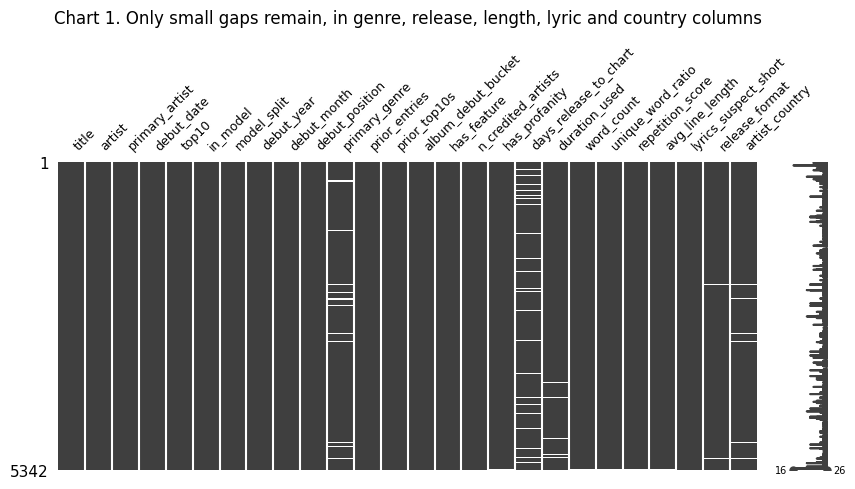

In [49]:
# Chart 1: each white line is a missing value.
ax = msno.matrix(songs, figsize=(10, 4), fontsize=9)
ax.set_title('Chart 1. Only small gaps remain, in genre, release, length, lyric and country columns', pad=100);

The Top 10 rate stays at about one in ten in all nine years.

In [50]:
# Songs and Top 10 rate for each debut year.
by_year = songs.groupby('debut_year').agg(songs=('title', 'size'), top10=('top10', 'sum'))
by_year['top10_rate'] = (by_year['top10'] / by_year['songs'] * 100).round(1)
by_year

,songs,top10,top10_rate
debut_year,,,
2018,595,67,11.3
2019,518,48,9.3
2020,674,65,9.6
2021,647,63,9.7
2022,629,77,12.2
2023,613,58,9.5
2024,617,63,10.2
2025,570,49,8.6
2026,479,29,6.1


### Summary: what we changed and why

| Column | Problem | What we did | Why |
|---|---|---|---|
| all | the archive has one row per song **per week** | Step 2: `groupby` + `agg` to one row per credit | we study songs, not weeks |
| `title`, `artist` | 34 songs were listed under two credits (e.g. "Kanye West" → "Ye") | Step 3: a hand-checked rename list | their weeks were split and their peaks looked lower; 5,377 → 5,342 songs, Top 10 521 → 519 |
| `artist` | one credit can name several artists | Step 4: replace the separators, then `.str.split` | we need each artist's history; the number of artists is used in Q6b |
| `artist` | three names contain a separator but are one act | Step 4: protected-names list | " x " would cut "Lil Nas X"; Sam & Dave and Sonny & Cher would leak into Dave's and Cher's histories |
| `prior_top10s` | the history could count the song itself, later songs, or songs that only became hits after this song debuted | Step 5: count only songs that debuted strictly earlier **and** were already Top 10 hits by this song's debut week; two checks | otherwise the predictor would give away the answer |
| `top10` | 99 songs are still on the chart | Step 6: left out of all tests | their peak is not final |
| `primary_genre` | hundreds of detailed labels | Step 8: keyword rules + vote counts | broad groups we can compare |
| `primary_genre` | ties between genres | Step 8: the artist's votes break ties, otherwise "mixed" | no random choice (like alphabetical order) |
| `duration` | 382 album-length or placeholder lengths | Step 9: MusicBrainz length; 306 fixed | needed for the cut-short check and Phase 2, Q4 |
| lyrics | some uploads are cut short | Step 9: flag the slowest 2% in each genre | used for the check in Q4 |
| lyrics | section tags like `[Chorus]` | Step 10: cut out with a simple loop | tags are not lyrics |
| lyric measures | 32 songs have no lyrics | Step 10: left blank, not 0 | a missing song is not a zero-word song |

Two problems were fixed earlier, when our scripts collected the data, so the raw files already
include the fixes. LRCLIB sometimes returned an instrumental upload for a song with vocals (we
prefer a version with lyrics), and a search by title alone could return another artist's song with
the same name (we require the artist to match).

**So what:** after cleaning there is one row per song, every predictor only uses what was known at
debut, and every remaining gap is explained.

## 4. Phase 1 recap: what the Team Assignment found

In the Team Assignment we tested ten factors, one at a time, on the 2018-2024 songs. Here we keep
its five charts and the main numbers. The full write-up is in the Team Assignment notebook.

**How to read the results (plain English).**

- **Null hypothesis (H₀): The assumption that this factor makes no difference. We only claim a finding when the data make that default very unlikely.
- **p-value:** how surprising the result would be if the factor really made no difference. Below 0.05, we treat the difference as real ("reject the null").
- **Cramér's V (0 to 1):** how *big* the effect is. With thousands of songs, even tiny differences get small p-values, so V tells us whether a difference actually matters: under 0.1 is negligible, 0.1 to 0.3 is small.
- **Chi-square test:** compares Top 10 rates across groups, such as genres.
- **Mann-Whitney test:** compares a number, such as word count, between hits and non-hits without assuming a bell curve.

These two tests are not part of the class material (see *Tools beyond the course material* at the
top), so each one lives in one short helper function.

In [51]:
# The 2018-2024 training songs are used for every Phase 1 test.
# .copy() lets us add columns to train safely.
train = songs[songs['model_split'] == 'train'].copy()
test = songs[songs['model_split'] == 'test']
print('train (2018-2024):', len(train), 'songs,', train['top10'].sum(), 'Top 10')
print('test (2025-2026):', len(test), 'songs, held out')
print('Top 10 rate in train (%):', round(train['top10'].mean() * 100, 1))

train (2018-2024): 4293 songs, 441 Top 10
test (2025-2026): 950 songs, held out
Top 10 rate in train (%): 10.3


In [52]:
# Chi-square test: does the Top 10 rate differ between groups (e.g. genres)?
def chi_square_test(data, column, other_column='top10'):
    # Step 1: count the songs in each combination, e.g. genre x (Top 10 or not).
    counts = pd.crosstab(data[column], data[other_column])
    # Step 2: compare these counts with what we'd expect if the groups made no difference.
    # The p-value is how likely a gap this big would be by pure chance (below 0.05: we call it real).
    chi2, p_value, dof, expected = stats.chi2_contingency(counts)
    # Step 3: Cramer's V says how strong the link is, from 0 (none) to 1 (perfect).
    # It adjusts for the number of songs, so a big sample doesn't look stronger than it is.
    cramers_v = np.sqrt(chi2 / (counts.values.sum() * (min(counts.shape) - 1)))
    print(f"chi-square = {chi2:.1f}, p = {p_value:.2e}, Cramer's V = {cramers_v:.3f}")
    return p_value, cramers_v

In [53]:
# Mann-Whitney test: is a number (e.g. word count) different for Top 10 songs?
def mann_whitney_test(data, column):
    # Step 1: split the values into Top 10 songs and all other songs, without blanks.
    hits = data[data['top10'] == True][column].dropna()
    others = data[data['top10'] == False][column].dropna()
    # Step 2: the test ranks all the values together and checks if one group sits higher.
    # It uses ranks, not averages, so a few extreme songs can't drive the result.
    u_stat, p_value = stats.mannwhitneyu(hits, others)
    # Step 3: show the two medians (the middle value of each group) and the p-value.
    print(f'{column}: median Top 10 = {hits.median():.3f}, median others = {others.median():.3f}, p = {p_value:.2e}')
    return hits.median(), others.median(), p_value

### 4.1 Genre

Is the Top 10 rate different for each broad genre?

In [54]:
# Top 10 rate for each genre. The mean of True/False is a share, so x100 gives a percent.
q1 = train.groupby('primary_genre').agg(songs=('top10', 'size'), top10_rate=('top10', 'mean'))
q1['top10_rate'] = (q1['top10_rate'] * 100).round(1)
q1 = q1.sort_values('top10_rate', ascending=False)
q1_p, q1_v = chi_square_test(train, 'primary_genre')
q1

chi-square = 89.1, p = 7.09e-16, Cramer's V = 0.146


,songs,top10_rate
primary_genre,,
pop,796,18.7
dance/electronic,106,16.0
rock/alternative,94,13.8
R&B,321,9.3
hip-hop/rap,2017,8.8
other,97,8.2
mixed,46,6.5
Latin,189,5.8
country,510,5.3


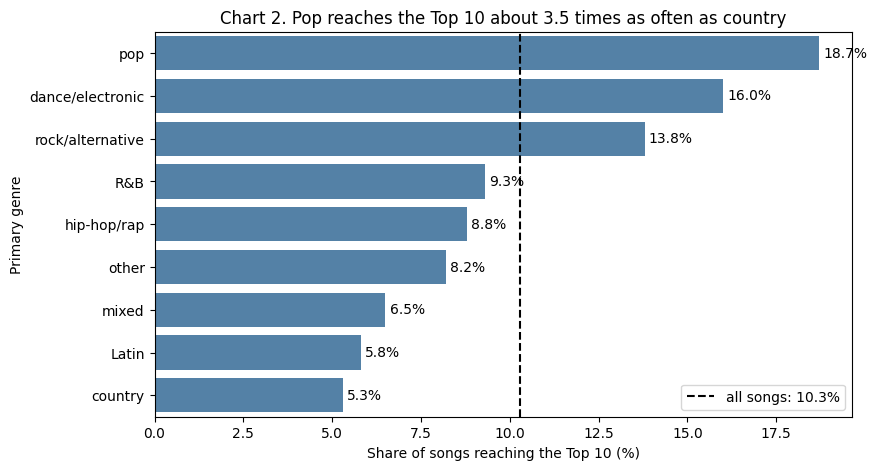

In [55]:
# Chart 2: Top 10 rate by genre. The dashed line is the rate for all songs.
overall = round(train['top10'].mean() * 100, 1)

plt.figure(figsize=(9, 5))
ax = sns.barplot(x='top10_rate', y='primary_genre', data=q1.reset_index(), color='steelblue')
# Write each value at the end of its bar.
ax.bar_label(ax.containers[0], fmt='%.1f%%', padding=3)
plt.axvline(overall, color='k', linestyle='--', label='all songs: ' + str(overall) + '%')
plt.title('Chart 2. Pop reaches the Top 10 about 3.5 times as often as country')
plt.xlabel('Share of songs reaching the Top 10 (%)')
plt.ylabel('Primary genre')
plt.legend()
plt.show()

**Answer.** Yes, a bit. Pop is highest at **18.7%** and country is lowest at **5.3%**
(p = 7.1×10⁻¹⁶, V = 0.146). Hip-hop/rap is the biggest genre, but only 8.8% of its songs reach the
Top 10.

### 4.2 The artist's track record

Do earlier Top 10 hits predict the next one?

In [56]:
# Group the artists by how many Top 10 hits they had before this song.
train['prior_bucket'] = '10+'
train.loc[train['prior_top10s'] <= 9, 'prior_bucket'] = '5-9'
train.loc[train['prior_top10s'] <= 4, 'prior_bucket'] = '1-4'
train.loc[train['prior_top10s'] == 0, 'prior_bucket'] = '0'

q2 = train.groupby('prior_bucket').agg(songs=('top10', 'size'), top10_rate=('top10', 'mean'))
q2['top10_rate'] = (q2['top10_rate'] * 100).round(1)
# Put the groups in order.
q2 = q2.reindex(['0', '1-4', '5-9', '10+'])
q2_p, q2_v = chi_square_test(train, 'prior_bucket')
q2

chi-square = 107.1, p = 4.62e-23, Cramer's V = 0.158


,songs,top10_rate
prior_bucket,,
0,1524,5.8
1-4,1416,8.9
5-9,456,13.4
10+,897,18.5


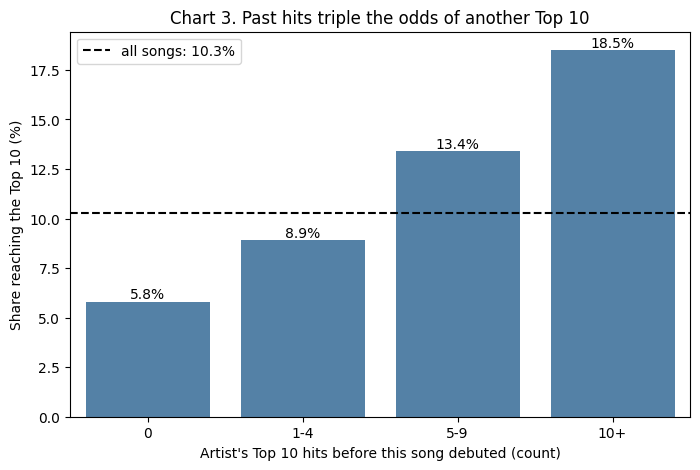

In [57]:
# Chart 3: Top 10 rate by the artist's earlier Top 10 hits.
plt.figure(figsize=(8, 5))
ax = sns.barplot(x='prior_bucket', y='top10_rate', data=q2.reset_index(), color='steelblue')
ax.bar_label(ax.containers[0], fmt='%.1f%%')
plt.axhline(overall, color='k', linestyle='--', label='all songs: ' + str(overall) + '%')
plt.title('Chart 3. Past hits triple the odds of another Top 10')
plt.xlabel("Artist's Top 10 hits before this song debuted (count)")
plt.ylabel('Share reaching the Top 10 (%)')
plt.legend()
plt.show()

**Answer.** Yes, and it is the strongest single factor: **5.8%** for artists with no earlier Top 10,
going up step by step to **18.5%** for artists with ten or more (p = 4.6×10⁻²³, V = 0.158). This
uses the fixed count from Step 5, which only counts hits the artist already had at debut. The fix
moved the middle groups by at most 0.2 points (1-4 earlier hits: 8.7% → 8.9%).

### 4.3 Album drops

Does releasing many songs in the same week change each song's chance?

In [58]:
# Top 10 rate by how many songs the artist debuted that week.
q3 = train.groupby('album_debut_bucket').agg(songs=('top10', 'size'), top10_rate=('top10', 'mean'))
q3['top10_rate'] = (q3['top10_rate'] * 100).round(1)
q3 = q3.reindex(['1', '2-4', '5-9', '10+'])
q3_p, q3_v = chi_square_test(train, 'album_debut_bucket')
q3

chi-square = 44.5, p = 1.16e-09, Cramer's V = 0.102


,songs,top10_rate
album_debut_bucket,,
1,2123,11.6
2-4,366,6.3
5-9,425,2.1
10+,1379,11.8


In [59]:
# The same rates, split into newcomers and established artists (at least one earlier Top 10).
train['artist_group'] = 'Newcomer (no earlier Top 10)'
train.loc[train['prior_top10s'] > 0, 'artist_group'] = 'Established (1+ earlier Top 10)'

q3_split = train.groupby(['album_debut_bucket', 'artist_group']).agg(
    songs=('top10', 'size'), top10_rate=('top10', 'mean')).reset_index()
q3_split['top10_rate'] = (q3_split['top10_rate'] * 100).round(1)
q3_split

,album_debut_bucket,artist_group,songs,top10_rate
0,1,Established (1+ earlier Top 10),994,17.2
1,1,Newcomer (no earlier Top 10),1129,6.6
2,10+,Established (1+ earlier Top 10),1235,12.7
3,10+,Newcomer (no earlier Top 10),144,4.2
4,2-4,Established (1+ earlier Top 10),237,7.6
5,2-4,Newcomer (no earlier Top 10),129,3.9
6,5-9,Established (1+ earlier Top 10),303,2.3
7,5-9,Newcomer (no earlier Top 10),122,1.6


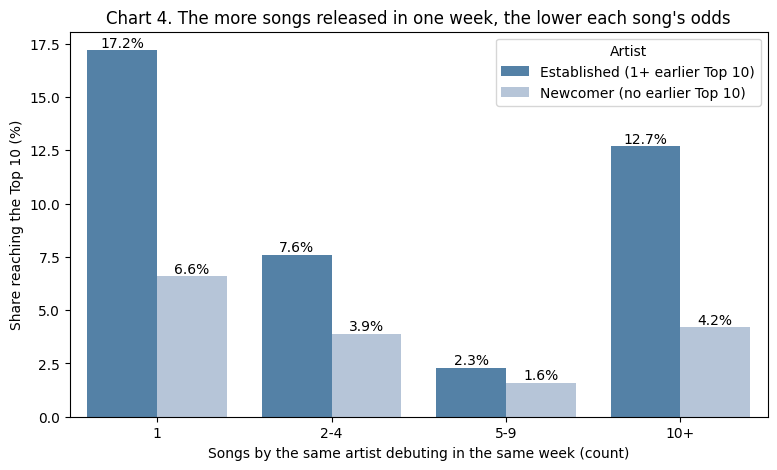

In [60]:
# Chart 4: Top 10 rate by album-drop size, newcomers vs established artists.
plt.figure(figsize=(9, 5))
ax = sns.barplot(x='album_debut_bucket', y='top10_rate', hue='artist_group', data=q3_split,
                 order=['1', '2-4', '5-9', '10+'], palette=['steelblue', 'lightsteelblue'],
                 hue_order=['Established (1+ earlier Top 10)', 'Newcomer (no earlier Top 10)'])
# One set of bars per artist group.
for bars in ax.containers:
    ax.bar_label(bars, fmt='%.1f%%')
plt.title("Chart 4. The more songs released in one week, the lower each song's odds")
plt.xlabel('Songs by the same artist debuting in the same week (count)')
plt.ylabel('Share reaching the Top 10 (%)')
plt.legend(title='Artist')
plt.show()

**Answer.** Yes (p = 1.2×10⁻⁹, V = 0.102). Songs released alone reach the Top 10 **11.6%** of the
time; songs in a drop of 5-9 songs only **2.1%**. The rise at 10+ songs (11.8%) only comes from
established artists. That left one open question, which Phase 2, Q2 answers: is the drop effect
real, or do big drops just come from different artists?

### 4.4 Lyric style

Are the lyrics of Top 10 songs different on four simple measures?

In [61]:
# Mann-Whitney test for each of the four lyric measures.
lyric_measures = ['word_count', 'unique_word_ratio', 'repetition_score', 'avg_line_length']
q4_results = []
for measure in lyric_measures:
    q4_results.append(mann_whitney_test(train, measure))

word_count: median Top 10 = 433.000, median others = 422.000, p = 7.31e-02
unique_word_ratio: median Top 10 = 0.348, median others = 0.361, p = 9.51e-05
repetition_score: median Top 10 = 0.433, median others = 0.419, p = 1.69e-01
avg_line_length: median Top 10 = 7.847, median others = 7.865, p = 2.01e-01


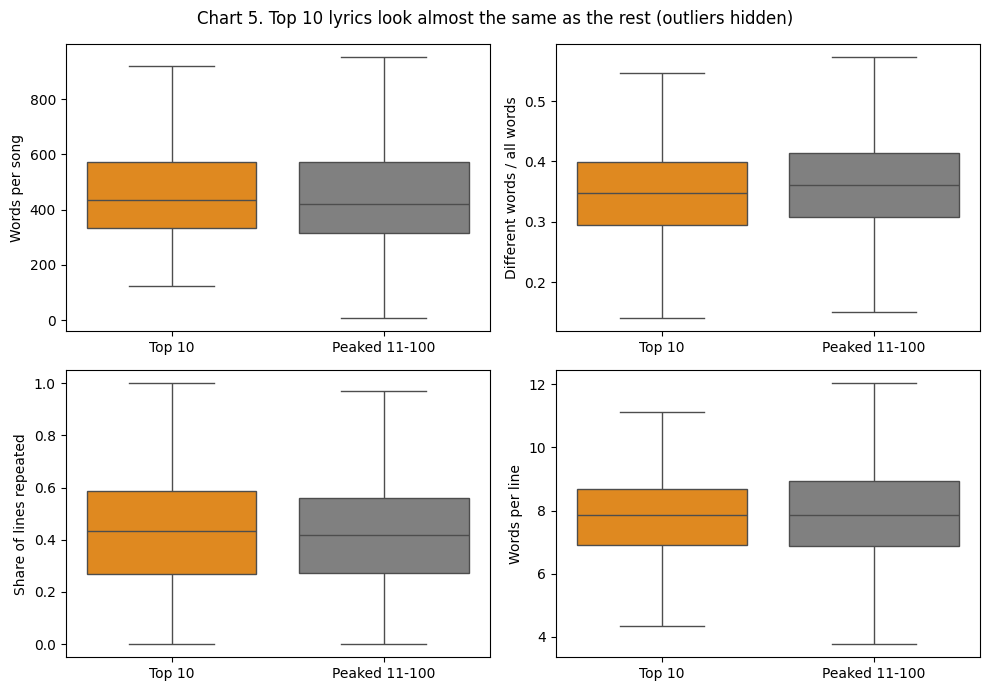

In [62]:
# Chart 5: box plots of the four lyric measures, Top 10 vs other songs.
train['result'] = train['top10'].map({True: 'Top 10', False: 'Peaked 11-100'})

# A 2 x 2 grid, one panel per measure. flatten() turns the grid into a list of 4 panels.
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
measures = [['word_count', 'Words per song'], ['unique_word_ratio', 'Different words / all words'],
            ['repetition_score', 'Share of lines repeated'], ['avg_line_length', 'Words per line']]
for ax, (column, label) in zip(axes.flatten(), measures):
    # Orange is Top 10, gray is the other songs.
    sns.boxplot(x='result', y=column, hue='result', data=train, showfliers=False, ax=ax,
                order=['Top 10', 'Peaked 11-100'], hue_order=['Top 10', 'Peaked 11-100'],
                palette=['darkorange', 'gray'], legend=False)
    ax.set_ylabel(label)
    ax.set_xlabel('')
plt.suptitle('Chart 5. Top 10 lyrics look almost the same as the rest (outliers hidden)')
plt.tight_layout()
plt.show()

In [63]:
# Check: leave out the songs whose lyrics may be cut short, and test again.
complete = train[train['lyrics_suspect_short'] == False]
print('songs left out:', len(train) - len(complete))
for measure in lyric_measures:
    mann_whitney_test(complete, measure)

songs left out: 84
word_count: median Top 10 = 435.000, median others = 426.000, p = 1.61e-01
unique_word_ratio: median Top 10 = 0.348, median others = 0.360, p = 2.62e-04
repetition_score: median Top 10 = 0.432, median others = 0.418, p = 1.81e-01
avg_line_length: median Top 10 = 7.849, median others = 7.898, p = 1.22e-01


**Answer.** Hardly. Only vocabulary is different (unique word ratio 0.348 vs 0.361,
p = 9.5×10⁻⁵). Word count, repetition and line length are not. Leaving out the lyrics that may be
cut short gives the same answer.

### 4.5 Release month

Is there a best month to release a hit, or is that really about album schedules?

In [64]:
# Top 10 rate by debut month: first all songs, then without big album drops.
q5_all = train.groupby('debut_month').agg(top10_rate=('top10', 'mean'))
q5_all['top10_rate'] = (q5_all['top10_rate'] * 100).round(1)
print('All songs:')
q5_all_p, q5_all_v = chi_square_test(train, 'debut_month')

# Remove drops of 5 or more songs.
small_drops = train[train['album_debut_bucket'].isin(['1', '2-4'])]
q5_small = small_drops.groupby('debut_month').agg(top10_rate=('top10', 'mean'))
q5_small['top10_rate'] = (q5_small['top10_rate'] * 100).round(1)
print('Without drops of 5+ songs:')
q5_small_p, q5_small_v = chi_square_test(small_drops, 'debut_month')

# Both versions side by side. .T flips the table so the months run across.
pd.DataFrame({'all songs': q5_all['top10_rate'], 'without drops of 5+': q5_small['top10_rate']}).T

All songs:
chi-square = 25.0, p = 9.15e-03, Cramer's V = 0.076
Without drops of 5+ songs:
chi-square = 5.5, p = 9.06e-01, Cramer's V = 0.047


debut_month,1,2,3,4,5,6,7,8,9,10,11,12
all songs,9.0,8.7,7.0,10.8,15.1,9.7,8.7,9.4,9.7,9.9,14.8,9.6
without drops of 5+,10.3,9.8,8.9,11.3,14.3,11.9,9.3,11.5,9.2,12.0,11.5,9.7


In [65]:
# The biggest same-artist release weeks in the training years.
drop_weeks = train.groupby(['primary_artist', 'debut_date']).agg(
    songs=('top10', 'size'), top10=('top10', 'sum')).reset_index()
drop_weeks.sort_values('songs', ascending=False).head(3)

,primary_artist,debut_date,songs,top10
2121,taylor swift,2024-05-04,31,10
1603,morgan wallen,2023-03-18,27,1
2111,taylor swift,2021-11-27,26,1


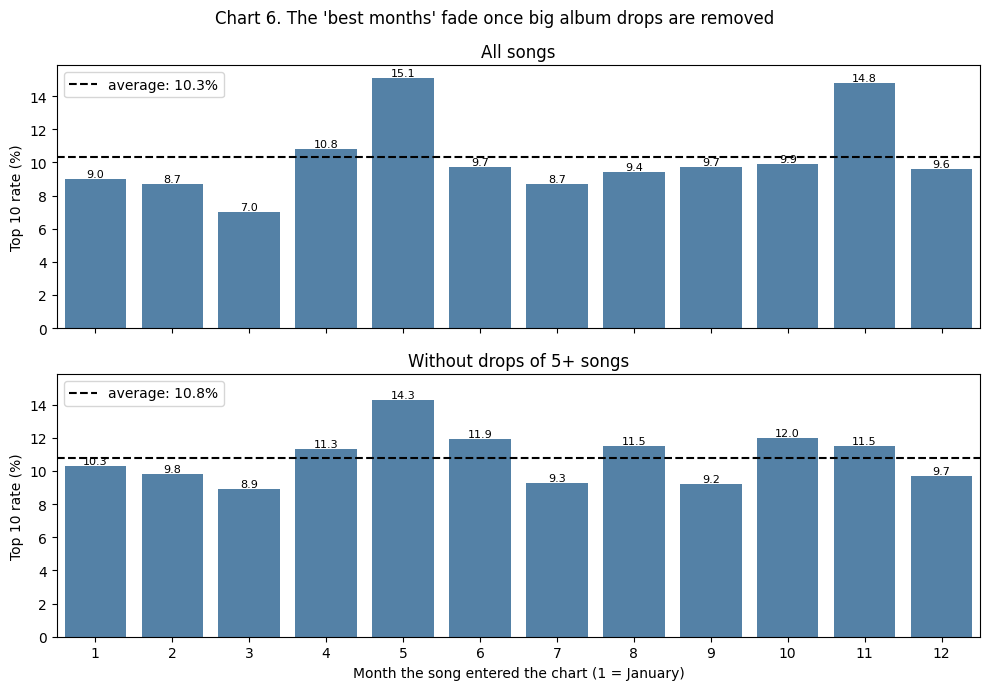

In [66]:
# Chart 6: Top 10 rate by month, with and without big drops. Each panel gets its own average.
small_average = round(small_drops['top10'].mean() * 100, 1)

# Two panels that share the same axes.
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True, sharey=True)
sns.barplot(x='debut_month', y='top10_rate', data=q5_all.reset_index(), color='steelblue', ax=axes[0])
axes[0].axhline(overall, color='k', linestyle='--', label='average: ' + str(overall) + '%')
axes[0].set_title('All songs')
sns.barplot(x='debut_month', y='top10_rate', data=q5_small.reset_index(), color='steelblue', ax=axes[1])
axes[1].axhline(small_average, color='k', linestyle='--', label='average: ' + str(small_average) + '%')
axes[1].set_title('Without drops of 5+ songs')
# The same labels on both panels.
for ax in axes:
    ax.bar_label(ax.containers[0], fmt='%.1f', fontsize=8)
    ax.set_ylabel('Top 10 rate (%)')
    ax.legend(loc='upper left')
axes[1].set_xlabel('Month the song entered the chart (1 = January)')
plt.suptitle("Chart 6. The 'best months' fade once big album drops are removed")
plt.tight_layout()
plt.show()

**Answer.** There is no reliable best month. May (15.1%) and November (14.8%) look strong
(p = 0.0092), partly because of superstar album weeks like Taylor Swift's 31-song week in May 2024.
Without drops of five or more songs, the month effect goes away (p = 0.906).

### 4.6 The other five questions

The other Team Assignment questions, tested again with one short table each.

In [67]:
# Q6: Top 10 rate (%) with and without a featured artist.
q6_p, q6_v = chi_square_test(train, 'has_feature')
(train.groupby('has_feature')['top10'].mean() * 100).round(1)

chi-square = 0.5, p = 4.94e-01, Cramer's V = 0.010


,top10
has_feature,
False,10.4
True,9.6


In [68]:
# Q6b: Top 10 rate (%) for credits with two or more artists vs one artist.
train['collaboration'] = train['n_credited_artists'] >= 2
collab_p, collab_v = chi_square_test(train, 'collaboration')
(train.groupby('collaboration')['top10'].mean() * 100).round(1)

chi-square = 0.0, p = 8.48e-01, Cramer's V = 0.003


,top10
collaboration,
False,10.2
True,10.4


In [69]:
# Q7: Top 10 rate (%) with and without profanity. Songs without lyrics can't be judged.
with_lyrics = train.dropna(subset=['has_profanity'])
q7_p, q7_v = chi_square_test(with_lyrics, 'has_profanity')
(with_lyrics.groupby('has_profanity')['top10'].mean() * 100).round(1)

chi-square = 0.1, p = 7.36e-01, Cramer's V = 0.005


,top10
has_profanity,
False,10.5
True,10.1


In [70]:
# Q8: days from release to chart, Top 10 songs vs the rest.
q8_hits, q8_others, q8_p = mann_whitney_test(train, 'days_release_to_chart')

days_release_to_chart: median Top 10 = 15.000, median others = 15.000, p = 4.96e-05


In [71]:
# Q9: the genre mix of Top 10 hits in 2018 and 2024. normalize='index' makes each year add up to 100%.
hits = train[train['top10'] == True].dropna(subset=['primary_genre'])
q9_p, q9_v = chi_square_test(hits, 'debut_year', 'primary_genre')
q9 = pd.crosstab(hits['debut_year'], hits['primary_genre'], normalize='index') * 100
q9.loc[[2018, 2024], ['hip-hop/rap', 'country']].round(1)

chi-square = 82.9, p = 1.31e-03, Cramer's V = 0.178


primary_genre,hip-hop/rap,country
debut_year,,
2018,56.7,0.0
2024,36.5,11.1


In [72]:
# Q10: Top 10 rate (%) by debut position, only for songs that debuted outside the Top 10
# (debuting at 1-10 already counts as a Top 10).
outside = train[train['debut_position'] > 10].copy()
outside['debut_bucket'] = '76-100'
outside.loc[outside['debut_position'] <= 75, 'debut_bucket'] = '51-75'
outside.loc[outside['debut_position'] <= 50, 'debut_bucket'] = '26-50'
outside.loc[outside['debut_position'] <= 25, 'debut_bucket'] = '11-25'
q10_p, q10_v = chi_square_test(outside, 'debut_bucket')
(outside.groupby('debut_bucket')['top10'].mean() * 100).round(1)

chi-square = 23.7, p = 2.86e-05, Cramer's V = 0.077


,top10
debut_bucket,
11-25,6.7
26-50,4.8
51-75,2.6
76-100,2.6


| Question | Top 10 rate or median | Result |
|---|---|---|
| Q6. Featured artist | 9.6% with vs 10.4% without | no effect (p = 0.494) |
| Q7. Explicit lyrics | 10.1% vs 10.5% | no effect (p = 0.736) |
| Q8. Days from release to chart | median 15 days for both; songs that are slow to chart are rarely hits | significant (p = 5.0×10⁻⁵) but small |
| Q9. Genre mix of Top 10 hits over time | hip-hop/rap 56.7% (2018) → 36.5% (2024); country 0% → 11.1% | changed (p = 0.0013) |
| Q10. Debut position | debuting at 1-10 already *is* a Top 10, so we only test songs that debuted lower: 6.7% (11-25) → 2.6% (76-100) | significant but weak (V = 0.077) |

Collaborations work like featured artists: songs credited to two or more artists reach the Top 10
10.4% of the time, against 10.2% for solo credits (Q6b, p = 0.848).

**Phase 1 takeaway:** *who* releases a song and *how* it is released matter much more than what the
lyrics look like. Q10 also taught us to check every feature against the definition of the target.
Our Phase 2 model follows that rule.

## 5. Phase 2: deeper questions

Phase 1 looked at one factor at a time. Phase 2 asks five deeper questions:

1. Can a model combine the first-week factors and spot hits in years it has never seen?
2. Is the album-drop effect real when we compare songs **by the same artist**?
3. How do hits move on the chart week by week, and has that changed?
4. Are songs getting shorter, and do hits follow?
5. Do artists from outside the US do better than US artists with the same track record?

Phase 2 uses every song with a final peak, including the 2025-2026 test songs.

In [73]:
# Phase 2 uses every song with a final peak: 2018-2024 (train) and 2025-2026 (test).
finished = songs[songs['in_model'] == True].copy()
print('songs with a final peak:', len(finished), '| Top 10:', finished['top10'].sum())
print('still on the chart (left out):', len(songs) - len(finished))
print('of those, already in the Top 10:', songs[songs['in_model'] == False]['top10'].sum())

# size = songs, sum = Top 10 songs, mean = Top 10 rate.
finished.groupby('model_split')['top10'].agg(['size', 'sum', 'mean']).round(3)

songs with a final peak: 5243 | Top 10: 497
still on the chart (left out): 99
of those, already in the Top 10: 22


,size,sum,mean
model_split,,,
test,950,56,0.059
train,4293,441,0.103


The test years have a lower Top 10 rate (5.9% vs 10.3%). Part of the reason is in the printout:
hits stay on the chart longer, so 22 recent hits are still charting and left out. This makes the
test harder, not easier.

### 5.1 Can we predict a Top 10 hit in its first week?

**Question.** Using only what is known in a song's first week, can a model pick out the songs that
will reach the Top 10? And does it beat a simple rule based on the artist's past hits?

**Method.** We follow the steps from the class classification notebook: build `X` and `y`, turn
categories into 0/1 columns with `pd.get_dummies`, fit a `LogisticRegression`, and predict the test
set. We train on 2018-2024 and test once on 2025-2026. The split is by year, not random, so the
model is tested on years it has never seen.

We compare two models:

- **Baseline:** the artist's history only (earlier Top 10 hits and earlier chart entries).
- **Full model:** the baseline plus genre, album-drop size, number of artists in the credit,
  featured artist, profanity, song length, days from release to chart, and four lyric measures.

**No peeking.** Every feature must be known in the first week, so `debut_position`,
`peak_position` and `weeks_on_chart` are not allowed. The cell below checks this: the printed list
must be empty.

In [74]:
# The model's inputs ("features"). Everything here is known in the song's debut week.
baseline_features = ['prior_top10s', 'prior_entries']
full_features = baseline_features + ['primary_genre', 'album_debut_bucket', 'n_credited_artists',
                                     'has_feature', 'has_profanity', 'duration_used', 'days_release_to_chart',
                                     'word_count', 'unique_word_ratio', 'repetition_score', 'avg_line_length']
print('features before dummies:', len(full_features))

# Leak check: these are only known after the debut week, so none of them may be a feature.
# The list below must be empty.
leak_cols = ['debut_position', 'peak_position', 'weeks_on_chart']
print([c for c in leak_cols if c in full_features])

features before dummies: 13
[]


As in class, we drop one 0/1 column per group: genres are compared with Latin, and drop sizes with
songs released alone.

In [75]:
# X is the inputs, y is the answer we want to predict.
X = finished[full_features].copy()
# The model needs numbers, so each genre and drop size becomes its own 0/1 column ("dummy").
# drop_first removes one column per group (Latin, and released alone) to compare the others with.
X = pd.get_dummies(X, columns=['primary_genre', 'album_debut_bucket'], drop_first=True)
# True/False becomes 1.0/0.0.
X = X.astype(float)
y = finished['top10']

# Split by year, not at random: the model learns from 2018-2024 and is tested on 2025-2026.
Xtrain = X[finished['model_split'] == 'train']
Xtest = X[finished['model_split'] == 'test']
ytrain = y[finished['model_split'] == 'train']
ytest = y[finished['model_split'] == 'test']
Xtrain.shape, Xtest.shape

((4293, 22), (950, 22))

We fill missing values with the **training songs'** medians, and we standardise the features with
the **training songs'** averages and spreads. The test songs reuse those same numbers, so nothing
about the test years leaks into the model.

In [76]:
# Step 1: fill missing values with the median (middle value) of the TRAINING songs, as in class.
# The test songs get the same training medians, so nothing about the test years leaks in.
train_medians = Xtrain.median()
Xtrain = Xtrain.fillna(train_medians)
Xtest = Xtest.fillna(train_medians)

# Step 2: standardise = subtract the average and divide by the spread (standard deviation).
# Then every feature has average 0 and spread 1, so their coefficients can be compared.
# Again we use the TRAINING numbers for both sets.
train_means = Xtrain.mean()
train_stds = Xtrain.std()
Xtrain = (Xtrain - train_means) / train_stds
Xtest = (Xtest - train_means) / train_stds
Xtrain.head(3).round(2)

,prior_top10s,prior_entries,n_credited_artists,has_feature,has_profanity,duration_used,days_release_to_chart,word_count,unique_word_ratio,repetition_score,...,primary_genre_country,primary_genre_dance/electronic,primary_genre_hip-hop/rap,primary_genre_mixed,primary_genre_other,primary_genre_pop,primary_genre_rock/alternative,album_debut_bucket_10+,album_debut_bucket_2-4,album_debut_bucket_5-9
1,-0.13,-0.13,-0.65,-0.51,-1.08,-0.41,-0.16,-0.66,-0.20,0.84,...,2.72,-0.16,-0.94,-0.1,-0.15,-0.48,-0.15,1.45,-0.31,-0.33
2,-0.55,-0.71,-0.65,-0.51,-1.08,0.46,-0.03,-0.50,-0.53,0.62,...,2.72,-0.16,-0.94,-0.1,-0.15,-0.48,-0.15,-0.69,-0.31,-0.33
3,1.73,1.19,-0.65,-0.51,-1.08,0.57,-0.16,-0.24,0.16,0.48,...,-0.37,-0.16,-0.94,-0.1,-0.15,2.10,-0.15,1.45,-0.31,-0.33


In [77]:
# Train the two logistic regression models and predict the test songs.
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix

# Logistic regression turns the features into a chance of a Top 10 (0 to 1)
# and predicts "Top 10" when that chance is above 0.5.
# 1. choose the model (same setting as in class)
baseline = LogisticRegression(solver='liblinear')
# 2. learn from the 2018-2024 songs, using artist history only
baseline.fit(Xtrain[baseline_features], ytrain)
# 3. predict the 2025-2026 songs
y_baseline = baseline.predict(Xtest[baseline_features])

# The full model: the same steps with all the debut-week features.
model = LogisticRegression(solver='liblinear')
model.fit(Xtrain, ytrain)
y_model = model.predict(Xtest)

**Why precision and recall, and not accuracy?** A model that always says "not a hit" is 94%
accurate on the test songs, and completely useless. **Precision** asks: of the songs the model
flagged, how many became hits? **Recall** asks: of the real hits, how many did the model catch? We
count both by hand from the confusion matrix, with the formulas in the comments.

In [78]:
# How many real hits are in the test set, and how accurate is it to always say "not a hit"?
print('test songs:', len(ytest), '| real Top 10 hits:', ytest.sum())
print('accuracy of always saying "not a hit" (%):', round((1 - ytest.mean()) * 100, 1))

test songs: 950 | real Top 10 hits: 56
accuracy of always saying "not a hit" (%): 94.1


In [79]:
# Precision and recall for both models, counted by hand from each confusion matrix.
rows = []
for name, predicted in [['Baseline (artist history)', y_baseline], ['Full model', y_model]]:
    # Rows of the matrix are the real answer, columns are the prediction.
    mat = confusion_matrix(ytest, predicted)
    caught = mat[1, 1]
    false_alarms = mat[0, 1]
    missed = mat[1, 0]
    # precision = TP / (TP + FP): of the songs flagged, the share that were real hits
    precision = caught / (caught + false_alarms)
    # recall = TP / (TP + FN): of the real hits, the share the model flagged
    recall = caught / (caught + missed)
    rows.append([name, round(precision * 100, 1), round(recall * 100, 1), predicted.sum()])

scores = pd.DataFrame(rows, columns=['model', 'precision', 'recall', 'songs flagged as hits'])
scores

,model,precision,recall,songs flagged as hits
0,Baseline (artist history),19.6,16.1,46
1,Full model,42.9,26.8,35


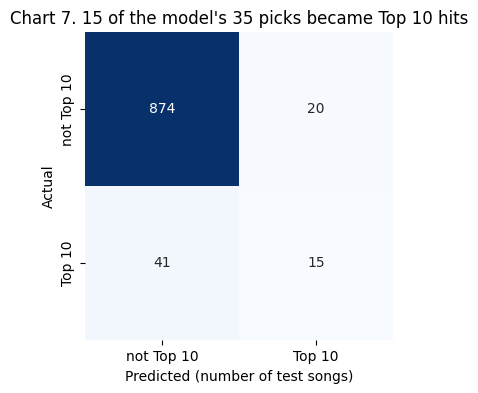

In [80]:
# Chart 7: the confusion matrix counts real answers (rows) against predictions (columns).
mat = confusion_matrix(ytest, y_model)

plt.figure(figsize=(5, 4))
# annot=True writes the counts in the boxes.
sns.heatmap(mat, square=True, annot=True, fmt='d', cbar=False, cmap='Blues',
            xticklabels=['not Top 10', 'Top 10'], yticklabels=['not Top 10', 'Top 10'])
plt.title("Chart 7. 15 of the model's 35 picks became Top 10 hits")
plt.xlabel('Predicted (number of test songs)')
plt.ylabel('Actual')
plt.show()

In [81]:
# The full model's coefficients: how much each feature pushes toward or away from a Top 10.
# The features are standardised, so each coefficient is the effect of a one-standard-deviation change.
coefficients = pd.DataFrame({'feature': Xtrain.columns, 'coefficient': model.coef_[0]})
coefficients = coefficients.sort_values('coefficient')
# The two strongest pushes away and the two strongest pushes toward a Top 10.
pd.concat([coefficients.head(2), coefficients.tail(2)]).round(2)

,feature,coefficient
21,album_debut_bucket_5-9,-0.55
8,unique_word_ratio,-0.26
0,prior_top10s,0.33
17,primary_genre_pop,0.44


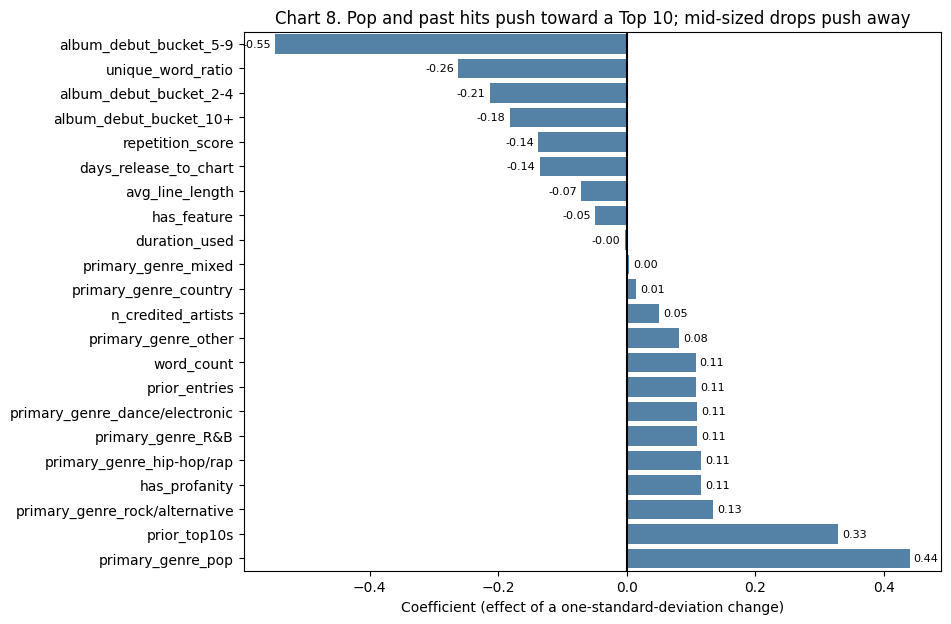

In [82]:
# Chart 8: all the coefficients. Left of 0 pushes away from a hit, right of 0 pushes toward one.
plt.figure(figsize=(9, 7))
ax = sns.barplot(x='coefficient', y='feature', data=coefficients, color='steelblue')
ax.bar_label(ax.containers[0], fmt='%.2f', padding=3, fontsize=8)
plt.axvline(0, color='k')
plt.title('Chart 8. Pop and past hits push toward a Top 10; mid-sized drops push away')
plt.xlabel('Coefficient (effect of a one-standard-deviation change)')
plt.ylabel('')
plt.show()

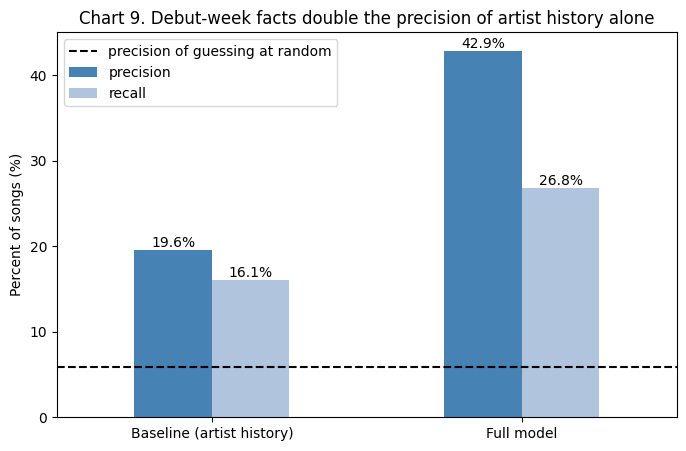

In [83]:
# Chart 9: precision and recall of the two models side by side.
ax = scores.set_index('model')[['precision', 'recall']].plot(kind='bar', figsize=(8, 5), rot=0,
                                                             color=['steelblue', 'lightsteelblue'])
# One set of bars per measure.
for bars in ax.containers:
    ax.bar_label(bars, fmt='%.1f%%')
plt.axhline(ytest.mean() * 100, color='k', linestyle='--', label='precision of guessing at random')
plt.title('Chart 9. Debut-week facts double the precision of artist history alone')
plt.xlabel('')
plt.ylabel('Percent of songs (%)')
plt.legend()
plt.show()

**Answer.** Yes. The full model clearly beats the baseline on both measures.

- **Precision 42.9% vs 19.6%.** The full model flagged 35 test songs, and 15 of them became Top 10
  hits. Picking songs at random would give 5.9%.
- **Recall 26.8% vs 16.1%.** It caught 15 of the 56 real hits; the baseline caught 9.
- **What drives it (Chart 8).** Being pop (+0.44) and the artist's earlier Top 10s (+0.33) push
  toward a hit. Being in a drop of 5-9 songs pushes away the most (−0.55). A bigger vocabulary
  (unique word ratio, −0.26) also pushes away, which matches Phase 1. Song length adds almost
  nothing once the other features are known.

The leak fix in Step 5 changed 444 songs' history counts but none of these scores. Only the
earlier-hits coefficient moved, from 0.34 to 0.33.

**Caveat.** The test set only has 56 hits, so one or two songs more or less move each measure by a
few points. The model uses the default cut-off (a chance above 0.5). A label that wants to catch
more hits could lower it and accept more false alarms.

Therefore, a model that only uses first-week facts finds hits about seven times better than
random. It is good for ranking songs for marketing attention, not for promising a hit. This meets
our success criterion: it beats the artist-history baseline on precision and recall.

### 5.2 The album-drop effect within the same artist

**Question.** Phase 1 found that songs in big album drops rarely reach the Top 10. But drops come
from certain artists, so the effect could really be about *who* drops albums. Here we hold the
artist fixed: for every artist who released songs **both** on their own **and** in a drop of five or
more songs in 2018-2024, we compare the two kinds.

In [84]:
# Label each song: released alone, or in a drop of 5+ songs. Drops of 2-4 are left out.
train['release_type'] = 'other'
train.loc[train['album_debut_bucket'] == '1', 'release_type'] = 'alone'
train.loc[train['album_debut_bucket'].isin(['5-9', '10+']), 'release_type'] = 'drop of 5+'
compare = train[train['release_type'] != 'other'].copy()

# Keep the artists who did both. nunique counts the different release types each artist used.
compare['types_used'] = compare.groupby('primary_artist')['release_type'].transform('nunique')
both = compare[compare['types_used'] == 2]
print('artists with songs of both kinds:', both['primary_artist'].nunique(), '| songs:', len(both))

artists with songs of both kinds: 63 | songs: 2273


For each artist, we work out the Top 10 rate of each kind of release and note which one did better.

In [85]:
# For each artist, the Top 10 rate (%) of songs released alone and songs in drops.
# unstack() turns the two release types into two columns, one row per artist.
per_artist = both.groupby(['primary_artist', 'release_type'])['top10'].mean().unstack() * 100

per_artist['verdict'] = 'tie'
per_artist.loc[per_artist['alone'] > per_artist['drop of 5+'], 'verdict'] = 'better alone'
per_artist.loc[per_artist['alone'] < per_artist['drop of 5+'], 'verdict'] = 'better in drops'
per_artist['verdict'].value_counts()

,count
verdict,
better alone,38
tie,17
better in drops,8


In [86]:
# Three well-known examples.
per_artist.loc[['drake', 'taylor swift', 'morgan wallen']].round(1)

release_type,alone,drop of 5+,verdict
primary_artist,,,
drake,70.0,26.5,better alone
taylor swift,17.6,20.2,better in drops
morgan wallen,54.5,5.0,better alone


In [87]:
# The ties, then a test on all these artists' songs pooled together.
ties = per_artist[per_artist['verdict'] == 'tie']
print('ties where both rates are 0%:', (ties['alone'] == 0).sum(), 'of', len(ties))
album_p, album_v = chi_square_test(both, 'release_type')
(both.groupby('release_type')['top10'].mean() * 100).round(1)

ties where both rates are 0%: 17 of 17
chi-square = 59.5, p = 1.24e-14, Cramer's V = 0.162


,top10
release_type,
alone,22.6
drop of 5+,9.7


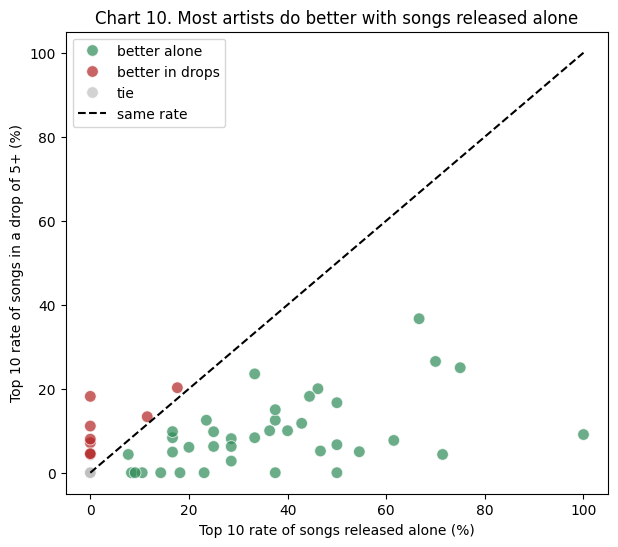

In [88]:
# Chart 10: one dot per artist. Dots below the dashed line did better alone.
plt.figure(figsize=(7, 6))
sns.scatterplot(x='alone', y='drop of 5+', hue='verdict', data=per_artist, s=70, alpha=0.7,
                hue_order=['better alone', 'better in drops', 'tie'],
                palette=['seagreen', 'firebrick', 'silver'])
# The dashed line is where both rates are equal.
plt.plot([0, 100], [0, 100], color='k', linestyle='--', label='same rate')
plt.title('Chart 10. Most artists do better with songs released alone')
plt.xlabel('Top 10 rate of songs released alone (%)')
plt.ylabel('Top 10 rate of songs in a drop of 5+ (%)')
plt.legend()
plt.show()

**Answer.** The effect is real: it holds within the same artist.

- **Artist by artist (the fair comparison).** Of 63 artists, 38 did better with songs released
  alone and only 8 did better in drops. All 17 ties are artists who never reached the Top 10
  either way. 70.0% of Drake's solo releases reached the Top 10, but only 26.5% of his album-drop
  songs; Morgan Wallen 54.5% vs 5.0%. Taylor Swift is one of the few exceptions (17.6% vs 20.2%).
- **All their songs together (supporting evidence).** Across these artists' songs, 22.6% of solo
  releases reached the Top 10, against 9.7% of album-drop songs (p = 1.2×10⁻¹⁴, V = 0.162).

**Caveat.** A song released on its own is usually the lead single, the track the label already
thinks is the strongest. So part of the gap is about which song was picked, not only how it was
released. Several "better in drops" artists had very few solo songs, so their 0% rates are shaky.

**Deduction:** even for the same artist, a song released alone is much more likely to reach the
Top 10. Lead singles should get their own release week.

**Note: singles vs album tracks.** Do songs released as
singles (the release format in MusicBrainz) beat album tracks, or is that just the drop effect
again?

In [89]:
# Singles vs album tracks (release format from MusicBrainz): how many of each debuted alone (%)?
formats = train[train['release_format'].isin(['Single', 'Album'])].copy()
formats['debuted_alone'] = formats['album_debut_bucket'] == '1'
(formats.groupby('release_format')['debuted_alone'].mean() * 100).round(1)

,debuted_alone
release_format,
Album,24.2
Single,90.1


In [90]:
# Top 10 rate (%) of singles and album tracks, all songs.
single_p, single_v = chi_square_test(formats, 'release_format')
(formats.groupby('release_format')['top10'].mean() * 100).round(1)

chi-square = 7.7, p = 5.39e-03, Cramer's V = 0.044


,top10
release_format,
Album,9.2
Single,12.0


In [91]:
# The same, only for songs that debuted alone.
solo_releases = formats[formats['debuted_alone'] == True]
solo_p, solo_v = chi_square_test(solo_releases, 'release_format')
(solo_releases.groupby('release_format')['top10'].mean() * 100).round(1)

chi-square = 0.1, p = 7.92e-01, Cramer's V = 0.006


,top10
release_format,
Album,11.4
Single,12.0


Across all training songs, singles reach the Top 10 more often than album tracks (12.0% vs 9.2%,
p = 0.0054). But 90.1% of singles debut alone, against 24.2% of album tracks. Among songs that
debut alone, the gap almost disappears (12.0% vs 11.4%, p = 0.79). So the singles advantage is
mostly the album-drop effect above, not the single format itself.

### 5.3 Chart paths: when do hits peak?

**Question.** How many weeks does a Top 10 hit take to reach its peak? Has peaking in the debut
week become more common? And do recent hits drop off faster? We use the weekly chart rows, as in the
class time-series notebook.

In [92]:
# Every chart week of every finished Top 10 song.
hits = finished[finished['top10'] == True][['title', 'artist', 'debut_date', 'debut_year']]
hit_weeks = pd.merge(weekly, hits, on=['title', 'artist'], how='inner')

# The first week each song reached its best position.
# transform('min') puts each song's best position on every one of its rows.
best = hit_weeks.groupby(['title', 'artist'])['position'].transform('min')
peak_weeks = hit_weeks[hit_weeks['position'] == best]
peak_dates = peak_weeks.groupby(['title', 'artist']).agg(peak_date=('chart_date', 'min')).reset_index()

# Weeks from debut to peak. // 7 turns days into whole weeks.
hits = pd.merge(hits, peak_dates, on=['title', 'artist'], how='left', validate='one_to_one')
hits['weeks_to_peak'] = (hits['peak_date'] - hits['debut_date']).dt.days // 7
hits['weeks_to_peak'].describe().round(1)

,weeks_to_peak
count,497.0
mean,7.6
std,20.0
min,0.0
25%,0.0
50%,0.0
75%,11.0
max,261.0


In [93]:
# How quickly do hits peak?
print('peaked in the debut week (%):', round((hits['weeks_to_peak'] == 0).mean() * 100, 1))
print('peaked within 4 weeks (%):', round((hits['weeks_to_peak'] <= 4).mean() * 100, 1))
print('took more than 30 weeks to peak:', (hits['weeks_to_peak'] > 30).sum())

peaked in the debut week (%): 58.4
peaked within 4 weeks (%): 67.8
took more than 30 weeks to peak: 31


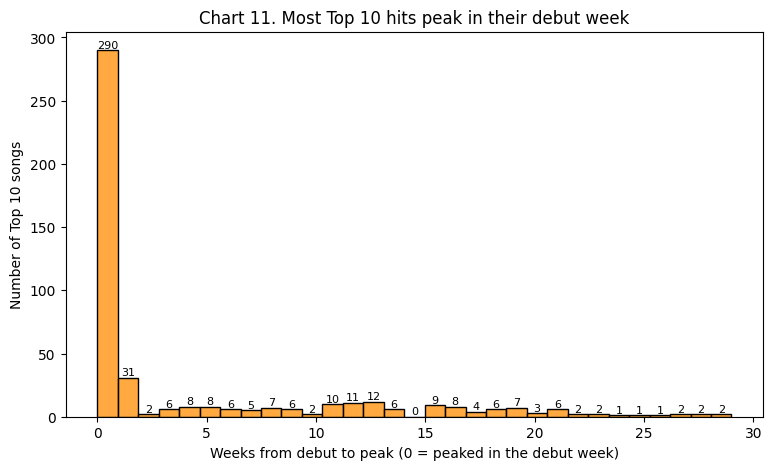

In [94]:
# Chart 11: weeks from debut to peak. The 31 very slow climbers are left off the chart.
plt.figure(figsize=(9, 5))
ax = sns.histplot(hits[hits['weeks_to_peak'] <= 30]['weeks_to_peak'], bins=31, color='darkorange')
# The number of songs above each bar.
ax.bar_label(ax.containers[0], fontsize=8)
plt.title('Chart 11. Most Top 10 hits peak in their debut week')
plt.xlabel('Weeks from debut to peak (0 = peaked in the debut week)')
plt.ylabel('Number of Top 10 songs')
plt.show()

The 31 slow climbers include holiday songs that peak in a later December (The Ronettes' "Sleigh
Ride" peaked 261 weeks after its 2018 debut) and sleeper hits like Taylor Swift's "Cruel Summer"
(216 weeks) and Glass Animals' "Heat Waves" (60 weeks).

Next, the share of each year's hits that peaked in their debut week. We group by year with
`resample('YE')` on a date index.

In [95]:
# Share of each year's hits that peaked in their debut week. 2026 is left out: its hits are still young.
hits['debut_at_peak'] = hits['weeks_to_peak'] == 0
complete_years = hits[hits['debut_year'] <= 2025]
# resample('YE') groups the dates by year, as in the class time-series notebook.
at_peak_by_year = complete_years.set_index('debut_date')['debut_at_peak'].resample('YE').mean() * 100
# Show 2018 instead of 2018-12-31.
at_peak_by_year.index = at_peak_by_year.index.year
at_peak_by_year.round(1)

,debut_at_peak
debut_date,
2018,46.3
2019,33.3
2020,63.1
2021,60.3
2022,63.6
2023,62.1
2024,68.3
2025,57.8


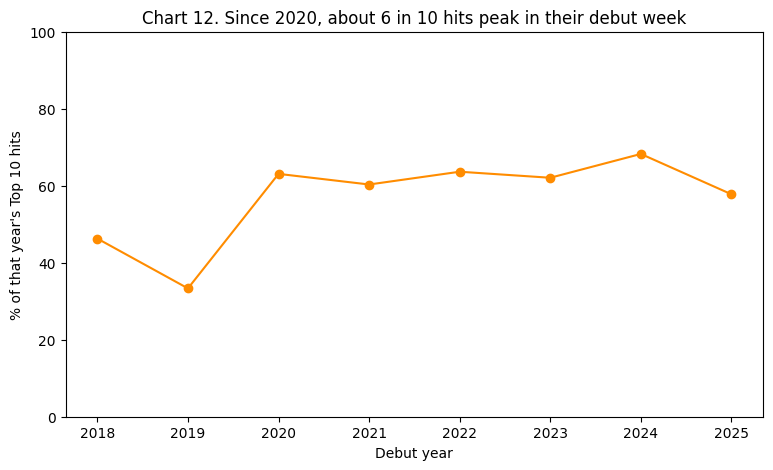

In [96]:
# Chart 12: share of each year's Top 10 hits that peaked in their debut week. 'o-' means dots joined by a line.
plt.figure(figsize=(9, 5))
at_peak_by_year.plot(style='o-', color='darkorange')
plt.title('Chart 12. Since 2020, about 6 in 10 hits peak in their debut week')
plt.xlabel('Debut year')
plt.ylabel("% of that year's Top 10 hits")
plt.ylim(0, 100)
plt.show()

Last, the typical path of a hit: the median chart position in each week after debut, for older and
newer hits.

In [97]:
# The typical path of a hit: its median chart position in each week after debut (0 = debut week).
hit_weeks['week_number'] = (hit_weeks['chart_date'] - hit_weeks['debut_date']).dt.days // 7
path = hit_weeks[(hit_weeks['debut_year'] <= 2025) & (hit_weeks['week_number'] <= 30)].copy()

# Two eras: older and newer hits.
path['era'] = '2022-2025'
path.loc[path['debut_year'] <= 2021, 'era'] = '2018-2021'
path = path.groupby(['era', 'week_number']).agg(median_position=('position', 'median'),
                                                songs_still_charting=('title', 'size')).reset_index()
path[path['week_number'].isin([0, 10, 20, 30])]

,era,week_number,median_position,songs_still_charting
0,2018-2021,0,8.0,243
10,2018-2021,10,14.0,187
20,2018-2021,20,13.0,135
30,2018-2021,30,18.0,85
31,2022-2025,0,7.0,243
41,2022-2025,10,22.5,172
51,2022-2025,20,18.0,114
61,2022-2025,30,21.0,72


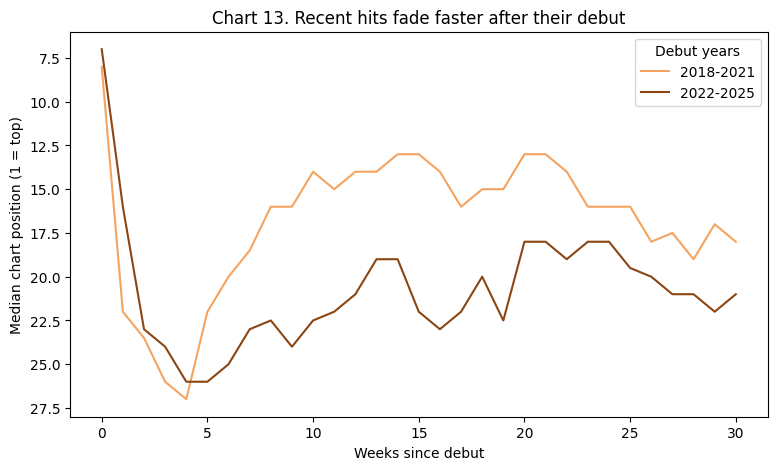

In [98]:
# Chart 13: median chart position by week since debut, older vs newer hits.
plt.figure(figsize=(9, 5))
sns.lineplot(x='week_number', y='median_position', hue='era', data=path,
             hue_order=['2018-2021', '2022-2025'], palette=['sandybrown', 'saddlebrown'])
# Put position 1 at the top, like the real chart.
plt.gca().invert_yaxis()
plt.title('Chart 13. Recent hits fade faster after their debut')
plt.xlabel('Weeks since debut')
plt.ylabel('Median chart position (1 = top)')
plt.legend(title='Debut years')
plt.show()

*Caveat: the later weeks only include songs still on the chart, so the right side of Chart 13 shows
the hits that lasted, not every hit.*

**Answer.**

- **Most hits peak right away.** The median Top 10 hit peaks in its debut week: 58.4% do, and about
  two-thirds peak within four weeks (Chart 11).
- **This has become more common.** 46.3% of 2018 hits peaked in their debut week, 60-68% in
  2020-2024, and 57.8% in 2025 (Chart 12). 2019 (33.3%) is the exception.
- **Recent hits drop off faster.** Both groups debut around position 7-8 and fall to the mid-20s
  within four weeks. Hits from 2018-2021 then climbed back to about 13-14 by weeks 10-20; hits from
  2022-2025 stayed around 18-24 (Chart 13).

**Deduction:** a hit's fate is usually decided in release week, and recent hits rarely get a second
wind. Marketing that comes after the debut is mostly too late, which is also why a first-week
model (5.1) is the right tool.

### 5.4 Are songs getting shorter?

**Question.** Streaming pays per play, and people often say that pushes songs to be shorter. Can we
see that on the Hot 100, and are Top 10 hits shorter than other songs?

In [99]:
# Median song length (minutes) per year, Top 10 vs other songs.
# 2026 is left out of the yearly views: only 11 of its finished songs are Top 10 hits.
finished['minutes'] = finished['duration_used'] / 60
complete_years = finished[finished['debut_year'] <= 2025]
length_by_year = complete_years.groupby(['debut_year', 'top10'])['minutes'].median().unstack().round(2)
length_by_year.columns = ['others', 'Top 10']
length_by_year

,others,Top 10
debut_year,,
2018,3.38,3.58
2019,3.25,3.18
2020,3.20,3.35
2021,3.30,3.48
2022,3.17,3.31
2023,3.25,3.33
2024,3.22,3.53
2025,3.17,3.32


In [100]:
# Are Top 10 songs longer? We test the training years. [2] keeps only the p-value.
train['minutes'] = train['duration_used'] / 60
length_p = mann_whitney_test(train, 'minutes')[2]

minutes: median Top 10 = 3.383, median others = 3.250, p = 2.85e-04


In [101]:
# Median length (minutes) of all songs in 2018 and in 2025.
finished[finished['debut_year'].isin([2018, 2025])].groupby('debut_year')['minutes'].median().round(2)

,minutes
debut_year,
2018,3.40
2025,3.18


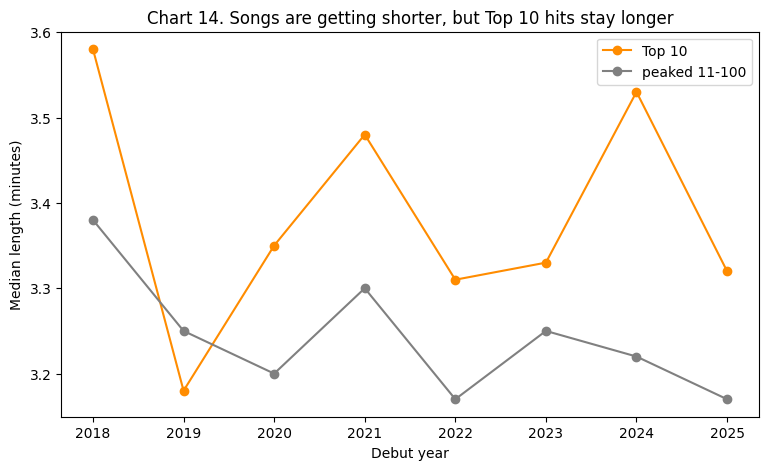

In [102]:
# Chart 14: median song length by year, Top 10 vs other songs.
plt.figure(figsize=(9, 5))
plt.plot(length_by_year.index, length_by_year['Top 10'], 'o-', color='darkorange', label='Top 10')
plt.plot(length_by_year.index, length_by_year['others'], 'o-', color='gray', label='peaked 11-100')
plt.title('Chart 14. Songs are getting shorter, but Top 10 hits stay longer')
plt.xlabel('Debut year')
plt.ylabel('Median length (minutes)')
plt.legend()
plt.show()

**Answer.** Songs on the chart are getting a little shorter, but hits are not.

- The median song went from **3:24** in 2018 to **3:11** in 2025, about 13 seconds
  shorter.
- Top 10 hits were *longer* than other songs in 7 of the 8 years. In 2018-2024 the medians were
  3:23 vs 3:15 (p = 2.9×10⁻⁴).

**Caveat.** The length comes from LRCLIB or MusicBrainz and may be the album version, not a radio
edit. In the model (5.1), length adds almost nothing once genre and artist are known. So the gap is
mostly about *which* songs become hits (pop and country songs run longer than rap), not the length
itself.

**Deduction:** making a song shorter is not a way into the Top 10.

### 5.5 Do artists from outside the US do better?

**Question.** Do songs whose lead artist is from outside the US reach the Top 10 more often than
songs by US artists? Artists who make the US chart from abroad are often already international
stars, so we compare US and outside-US artists **inside each group of earlier Top 10 hits**. The
country is the lead artist's country in MusicBrainz (Drake counts as Canada). We use the 2018-2024
training songs.

In [103]:
# Where is each song's lead artist from? Unknown countries stay blank and are left out.
train['origin'] = 'Outside the US'
train.loc[train['artist_country'] == 'US', 'origin'] = 'US'
train.loc[train['artist_country'].isna(), 'origin'] = np.nan
with_origin = train.dropna(subset=['origin'])
print('training songs with no known artist country (left out):', train['origin'].isna().sum())

q_origin = with_origin.groupby('origin').agg(songs=('top10', 'size'), top10_rate=('top10', 'mean'))
q_origin['top10_rate'] = (q_origin['top10_rate'] * 100).round(1)
origin_p, origin_v = chi_square_test(with_origin, 'origin')
q_origin

training songs with no known artist country (left out): 71
chi-square = 31.0, p = 2.63e-08, Cramer's V = 0.086


,songs,top10_rate
origin,,
Outside the US,800,15.8
US,3422,9.0


In [104]:
# The same comparison inside each group of artists with a similar number of earlier Top 10 hits,
# so the gap can't just come from outside-US artists having more past hits.
origin_groups = with_origin.groupby(['prior_bucket', 'origin']).agg(
    songs=('top10', 'size'), top10_rate=('top10', 'mean')).reset_index()
origin_groups['top10_rate'] = (origin_groups['top10_rate'] * 100).round(1)
for group in ['0', '1-4', '5-9', '10+']:
    print('earlier Top 10s:', group)
    chi_square_test(with_origin[with_origin['prior_bucket'] == group], 'origin')
origin_groups

earlier Top 10s: 0
chi-square = 0.5, p = 4.77e-01, Cramer's V = 0.018
earlier Top 10s: 1-4
chi-square = 9.0, p = 2.69e-03, Cramer's V = 0.080
earlier Top 10s: 5-9
chi-square = 4.1, p = 4.29e-02, Cramer's V = 0.096
earlier Top 10s: 10+
chi-square = 12.9, p = 3.31e-04, Cramer's V = 0.120


,prior_bucket,origin,songs,top10_rate
0,0,Outside the US,292,6.8
1,0,US,1189,5.6
2,1-4,Outside the US,212,14.6
3,1-4,US,1194,8.0
4,10+,Outside the US,220,26.8
5,10+,US,669,15.7
6,5-9,Outside the US,76,21.1
7,5-9,US,370,11.6


In [105]:
# How much do a few stars carry the gap? Top 10 songs per outside-US artist.
outside_us = with_origin[with_origin['origin'] == 'Outside the US']
star_hits = outside_us[outside_us['top10'] == True].groupby('primary_artist').size().sort_values(ascending=False)
top_three = star_hits.head(3)
print('their share of outside-US Top 10 songs (%):', round(top_three.sum() / star_hits.sum() * 100, 1))
top_three

their share of outside-US Top 10 songs (%): 48.4


,0
primary_artist,
drake,44
bad bunny,9
the weeknd,8


In [106]:
# The test again without those three artists. ~ means "not".
without_stars = with_origin[~with_origin['primary_artist'].isin(top_three.index)]
stars_p, stars_v = chi_square_test(without_stars, 'origin')
(without_stars.groupby('origin')['top10'].mean() * 100).round(1)

chi-square = 4.1, p = 4.26e-02, Cramer's V = 0.032


,top10
origin,
Outside the US,11.9
US,9.0


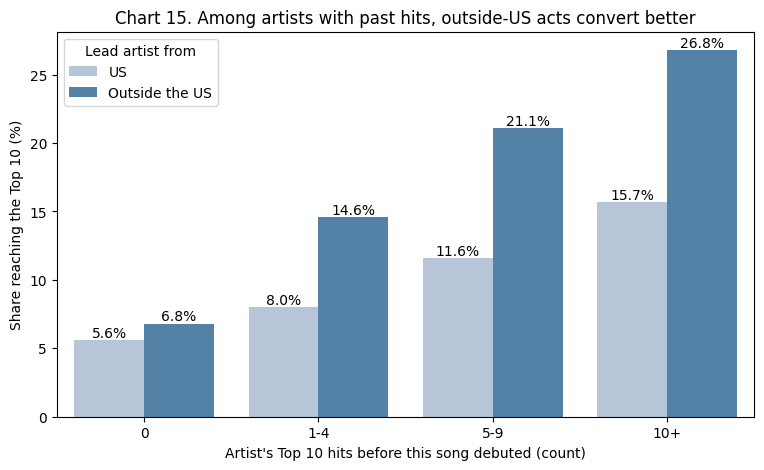

In [107]:
# Chart 15: US vs outside-US Top 10 rate within each group of earlier Top 10 hits.
plt.figure(figsize=(9, 5))
ax = sns.barplot(x='prior_bucket', y='top10_rate', hue='origin', data=origin_groups,
                 order=['0', '1-4', '5-9', '10+'], hue_order=['US', 'Outside the US'],
                 palette=['lightsteelblue', 'steelblue'])
# One set of bars per origin.
for bars in ax.containers:
    ax.bar_label(bars, fmt='%.1f%%')
plt.title('Chart 15. Among artists with past hits, outside-US acts convert better')
plt.xlabel("Artist's Top 10 hits before this song debuted (count)")
plt.ylabel('Share reaching the Top 10 (%)')
plt.legend(title='Lead artist from')
plt.show()

**Answer.** Yes for artists who already had hits, but a few stars carry a lot of the gap.

- **Overall.** Outside-US artists reach the Top 10 **15.8%** of the time (800 songs), US artists
  **9.0%** (3,422 songs): p = 2.6×10⁻⁸, but the effect is negligible (V = 0.086). We leave out 71
  songs whose lead artist has no country in MusicBrainz.
- **Same track record (Chart 15).** The gap holds in every group with earlier hits: 14.6% vs 8.0%
  at 1-4 (p = 0.0027), 21.1% vs 11.6% at 5-9 (p = 0.043), and 26.8% vs 15.7% at 10 or more
  (p = 0.00033). It doesn't show up for artists with no earlier hit (6.8% vs 5.6%, p = 0.48).
- **A few stars carry it.** Drake (44 Top 10 songs), Bad Bunny (9) and The Weeknd (8) made
  **48.4%** of all outside-US Top 10 songs. Without them the overall gap shrinks to 11.9% vs 9.0%
  (p = 0.043, V = 0.032).

**Caveat.** The 5-9 group only has 76 outside-US songs. A song by a US act featuring a foreign
artist counts as US, because we only use the lead artist's country.

**Deduction:** Being from outside the US doesn't help on its own. Established international stars do
unusually well on the US chart, but a newcomer from abroad does no better than a US newcomer.

## 6. Challenges

| Challenge | What went wrong, or could have | How we handled it |
|---|---|---|
| **One song, two credits** | Billboard sometimes changes a credit while the song is charting ("Kanye West" → "Ye"), which splits the song's weeks and makes its peak look lower | We checked every possible pair by hand and merged 34 songs with a written rename list (Step 3) |
| **Splitting artist credits** | " x " cut "Lil Nas X"; "&" put Sam & Dave into Dave's history | A list of separators plus three protected names, each one tested (Step 4) |
| **Matching by name across sources** | The lyrics site sometimes returned an instrumental version, or another artist's song with the same title | Every match has a 0-100 confidence score; we prefer versions with lyrics and require the artist to match |
| **Missing values** | Songs without lyrics could be scored as "0 words"; missing values counted as true in plain `if` checks | Lyric measures are left blank, never 0; we check for missing values on purpose |
| **Target leakage (giving away the answer)** | Debut position looked perfectly predictive (Q10); the artist history could count the song itself; Azaan's review found it also counted earlier songs that became hits only *after* the new song debuted (444 songs affected) | History only counts songs that debuted strictly earlier **and** were already Top 10 hits at debut (Step 5); lyrics come from the debut credit; the model checks for features from after debut; scaling uses training numbers only |
| **Hidden causes** | The month effect was really album schedules; the drop effect could have been about which artists drop albums | We tested again without big drops (4.5) and compared songs by the same artist (5.2) |
| **Songs still charting** | Recent songs have no final peak, and recent hits stay on the chart longest | Left out of every test; 2026 left out of the yearly trends; we noted that this lowers the test set's hit rate |
| **API limits and time** | MusicBrainz allows one request per second, so the download took about 5 hours and crashed once on a dropped connection | Our scripts save after every batch and pick up where they stopped |
| **Licensing** | Two of the three sources give no licence, and lyrics are copyrighted | Class use only; the data is not in our GitHub repository and no lyrics are printed |

## 7. Conclusion

**What we found.** Across 5,342 Hot 100 songs from 2018-2026, reaching the Top 10 mostly depends
on *who* releases a song and *how*, and it is usually decided in the first week:

1. **The artist's record and the genre set the starting chances**: 5.8% for newcomers vs 18.5% for
   artists with ten earlier hits; pop 18.7% vs country 5.3%.
2. **How the song is released moves them**: songs in mid-sized album drops reach the Top 10 only
   2.1% of the time, and the effect holds for the same artist (38 of 63 artists did better alone).
3. **Timing is all at the start**: 58.4% of hits peak in their debut week, and recent hits drop off
   faster.
4. **International stars do better**: among artists who already had hits, outside-US acts beat US
   acts with the same record, but Drake, Bad Bunny and The Weeknd carry nearly half of it.
5. **Many popular ideas show no effect**: lyric style, featured artists and collaborations, explicit
   lyrics and release month. Hits are slightly longer than other songs, but that is mostly
   because of their genre, so cutting songs short doesn't help.

**Did we meet our success criteria?** Yes. The cleaned dataset only uses first-week predictors,
with leak checks at every step, including the "later hits" leak found in review. The factors that
pass both p < 0.05 and V ≥ 0.1 are artist history, genre, album-drop size and the same-artist drop
comparison. The first-week model beats the artist-history baseline on the unseen 2025-2026 songs
(precision 42.9% vs 19.6%, recall 26.8% vs 16.1%).

**Recommendations.** Give lead singles their own release week; spend the promotion money in release
week; use the model to rank songs for attention; and stop relying on lyric tweaks, guest verses,
shorter songs or a "best month".

**Limitations.** Everything here is a link, not proof of cause: lead singles are picked because
labels believe in them. Genre comes from volunteer tags, and the test set only has 56 hits.

**Next steps.**

1. Score the model again on the full 2026 season once those songs are off the chart.
2. Add data a label has before release: audio features, pre-release streams, playlist adds.
3. Test what the lyrics *say* (mood, topic), not just their form.
4. Match songs across sources by ISRC code instead of by title, to recover the songs we couldn't
   match.

## 8. References

**Data sources**

1. Hollingshead, M. *Billboard Hot 100 archive*, JSON files for every Billboard Hot 100 chart,
   1958-2026. https://github.com/mhollingshead/billboard-hot-100 (accessed September 2026).
   No licence given by the repository.
2. *LRCLIB*, open lyrics database and API. https://lrclib.net/docs (accessed September 2026).
   No licence given on the public documentation page.
3. *MusicBrainz*, open music encyclopedia. https://musicbrainz.org/doc/MusicBrainz_API
   (accessed September 2026). Core data released under CC0;
   https://musicbrainz.org/doc/About/Data_License.

**Course material**

4. Soltaniehha, M. *Intro to Data Analytics* (BA780 course notebooks).
   https://github.com/soltaniehha/Intro-to-Data-Analytics. We followed
   `10-Machine-Learning-Overview/03-Classification` (dummies, logistic regression, fit and
   predict), `06-Exploring-Hand-written-Digits` (confusion-matrix heatmap),
   `11-Working-with-Time-Series` (`resample`), `09-Joins-and-APIs/02-Working-with-APIs`
   (`!unzip`), and `07-Visualization/Mevgal-Cleaning` and `08-EDA` for the cleaning and EDA style.

**Software**

5. McKinney, W. (2010). Data structures for statistical computing in Python. *pandas*.
6. Harris, C. R. et al. (2020). Array programming with NumPy. *Nature* 585, 357-362.
7. Virtanen, P. et al. (2020). SciPy 1.0: fundamental algorithms for scientific computing in
   Python. *Nature Methods* 17, 261-272.
8. Pedregosa, F. et al. (2011). Scikit-learn: machine learning in Python. *Journal of Machine
   Learning Research* 12, 2825-2830.
9. Hunter, J. D. (2007). Matplotlib: a 2D graphics environment. *Computing in Science &
   Engineering* 9(3), 90-95.
10. Waskom, M. (2021). seaborn: statistical data visualization. *Journal of Open Source
    Software* 6(60), 3021.
11. Bilogur, A. (2018). Missingno: a missing data visualization suite. *Journal of Open Source
    Software* 3(22), 547.

**Methods**

12. Cramér, H. (1946). *Mathematical Methods of Statistics*. Princeton University Press.
13. Mann, H. B. & Whitney, D. R. (1947). On a test of whether one of two random variables is
    stochastically larger than the other. *Annals of Mathematical Statistics* 18(1), 50-60.

**Project code.** The scripts in `scripts/` collected the raw files from the APIs. All the
cleaning and analysis is in this notebook.

## 9. Generative AI disclosure

We used Generative AI tools to help with several parts of this project. Here is how:

- **Code generation (Claude Code, in VS Code):** the data collection scripts in our GitHub repo (scripts/ folder)
  and the cleaning and analysis code in this notebook, Sections 3-5. This includes the Phase 2
  prediction model and Charts 7-15.
- **Writing (Claude Code + team):** we wrote the first drafts of the markdown explanations, the
  executive summary, the challenges table and the conclusion, then used AI to enhance them. We
  revised them to match our own reading of the results.
- **Planning and review (Claude + team):** Claude helped us plan the analysis, then checked the
  Phase 2 questions we came up with, validated them and reviewed our work to make sure it was coherent.
- **Debugging (Claude Code):** found and fixed errors along the way, such as artist names cut by a
  separator, missing values treated as true, and lyrics matched to the wrong version.
- **Team review (no AI):** When we reviewed our notebook, we discovered the "later hits" leak in
  the artist-history count (fixed in Step 5) and added the outside-US question (5.5) and the singles
  vs album tracks note (5.2). Claude Code rewrote the code in our class style.
- **Decisions made by the team:** which duplicate songs to merge, which artist names to protect,
  how to group genres, which questions to ask, the leak rules, and how to read the results.

We then restyled the code and text to match our team's style and the methods from class, and checked that every result stayed the same.

Our team has reviewed, edited and checked all AI-generated code and text, and made sure our
written explanations match the outputs, tables and charts in this notebook.